# Q1

The data in the table below shows the line-of-sight component of the velocity of a _star_ as observed from Earth as a function of time. (The planet is too faint to detect photometrically, let alone take a spectrum of!)

The data have first been corrected for the rotation of the Earth and its orbit around the Sun, i.e. to the frame of the barycentre of our Solar system. Then they have been corrected (by MH) to the barycentre of the remote system by removing a mean offset, so you may assume that, for these corrected data, 0 m/s is the average radial velocity of the star.

This is real data, but the orbit of this system is actually close to circular, so we will neglect the parameters associated with its ellipticity and assume a _circular_ orbit. The data can then be described by three numbers: a <mark>frequency or period</mark>, a <mark>phase</mark> and an <mark>amplitude</mark>.

Day 0 is arbitrary. The time is in <mark>days</mark> and the velocity is in units of <mark> _metres_/_second_</mark>.

In [1]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

# Adjust default font size so that labels are readable in plots
font = {'size': 18}
matplotlib.rc('font', **font)

In [2]:
import astropy.table

tab = astropy.table.Table.read('Planet.csv', format='ascii.csv')
tab

Day,Radial_Velocity,Radial_Velocity_Uncertainty
float64,float64,float64
2.67293,-50.85763971946289,1.3451385
2.80777,-55.37167780946289,1.4675213
2.96133,-59.88485757946289,1.8407817
3.62656,-31.755737709462892,1.1571392
3.73272,-23.92064897946289,0.9810482
3.90064,-10.60241834946289,1.2261995
4.60587,39.713584490537116,0.9482159
4.78459,46.14331777053712,1.077486
4.90837,49.837340900537114,1.3151617


In [3]:
# Convert columns to more useful format
time = tab['Day'].data
v = tab['Radial_Velocity'].data
err = tab['Radial_Velocity_Uncertainty'].data

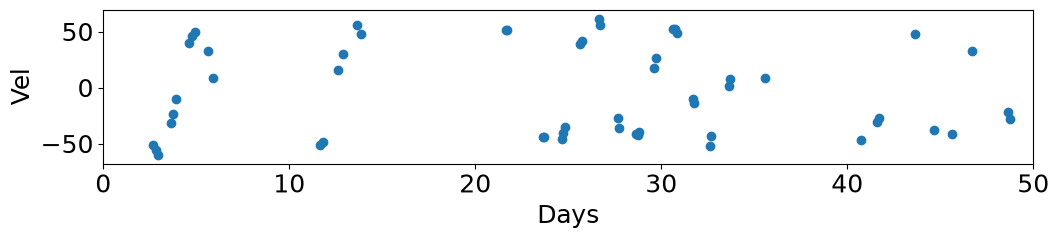

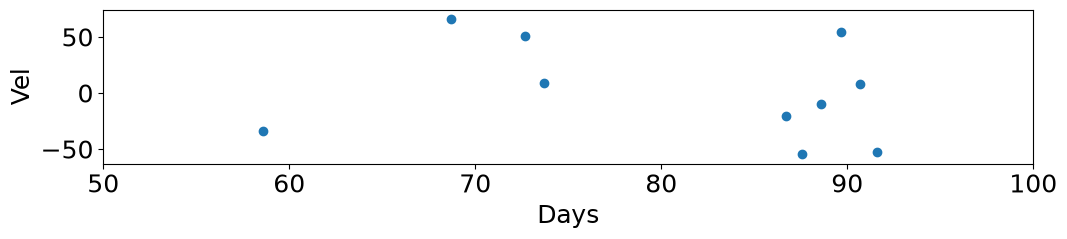

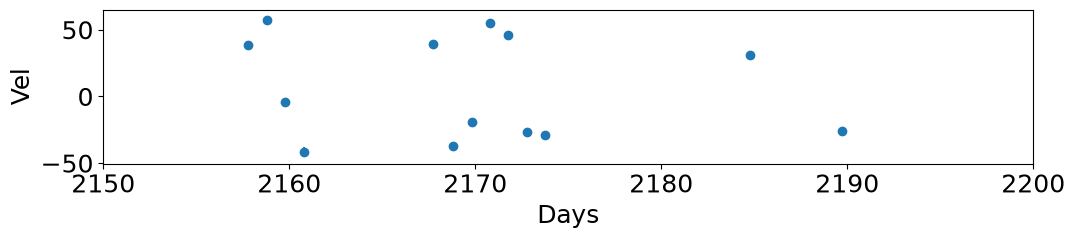

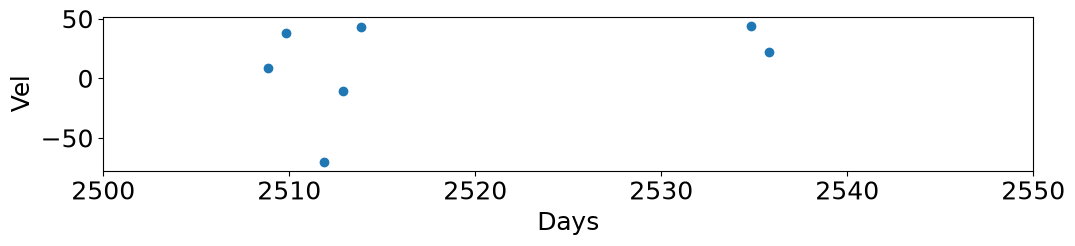

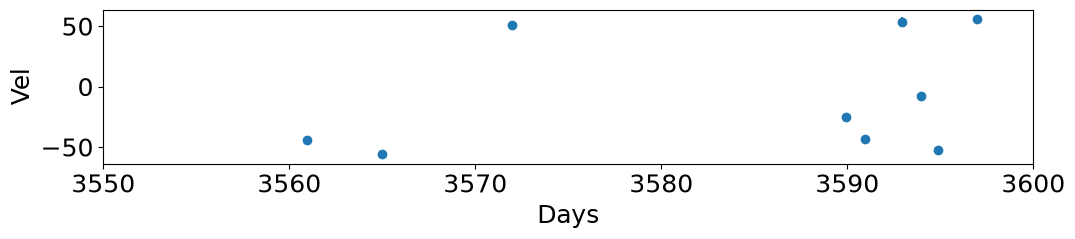

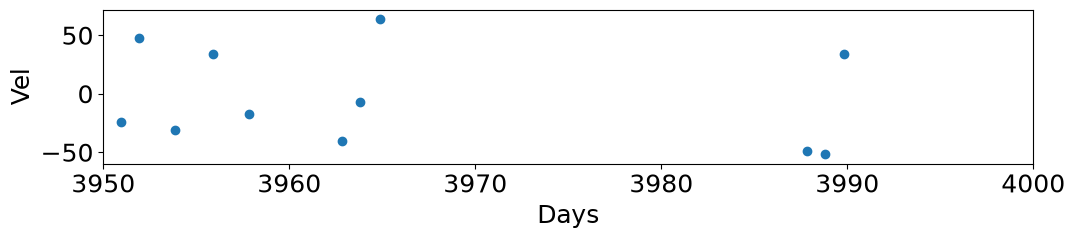

In [4]:
step = 50
for i,start in enumerate(np.arange(0, 6000, step)):
    end = start + step
    sel = np.logical_and(time > start, time < end)
    
    # Only plot the figure if there are a reasonable number of points in the range
    if len(time[sel]) > 6:
        fig = plt.figure(num=i, figsize=[12.,2.], dpi=100)
        plt.errorbar(time[sel],v[sel],err[sel],marker='o',ls='')
        plt.xlim((start,start+50))
        plt.xlabel("Days")
        plt.ylabel("Vel")

It looks like the first 50 days are amongst the best. You can use those for practice.

### Fitting the time series

Time series like these are very tricky; due to aliasing, there are many local minima.

So you will need some tricks to start your minimizer from a _good initial guess_. 

   * One of these "tricks" is to use your eyes: what is the range covered by the data? Can you guess the period? 

   * A second trick is to use a periodogram (one tuned for unevenly sampled data: FFT will not work well here - see Chapter 10 of SDMMMLA) to get an improved guess for the frequency or period.
    
Once you have made some guesses, for each guess plot your fit in two different ways 

   1. Over all the points (you can use the plotting scripts above).

   2. "Fold" all of the data. In other words, suppose you have fitted a period of 5 days. Then plot all data point with the x-axis having a range 0-5, and where a measurement taken at 8 days is plotted at 8 - (5 * 1) = 3, one at 14 days is plotted at 14- (2 * 5) = 4 and so on.

Now try using ``lmfit`` with the default least squares. Can you get it to converge to the correct answer? 

(If you have trouble, try working with only the first 50 days worth of data first, as a warmup).

<mark>_Show your final work as well as all your exploratory work and tests_. </mark>

Use as many cells as you need, mixing Markdown/LaTeX with code, as necessary.

---

## Start of my solution

### Starting with only first 50 days of data

In [5]:
import matplotlib.ticker as ticker

# Select only first 50 days of data to start
isWithinFirst50days = np.logical_and(time >= 0 , time <= 50)
t50 = time[isWithinFirst50days]
v50 = v[isWithinFirst50days]
err50 = err[isWithinFirst50days]

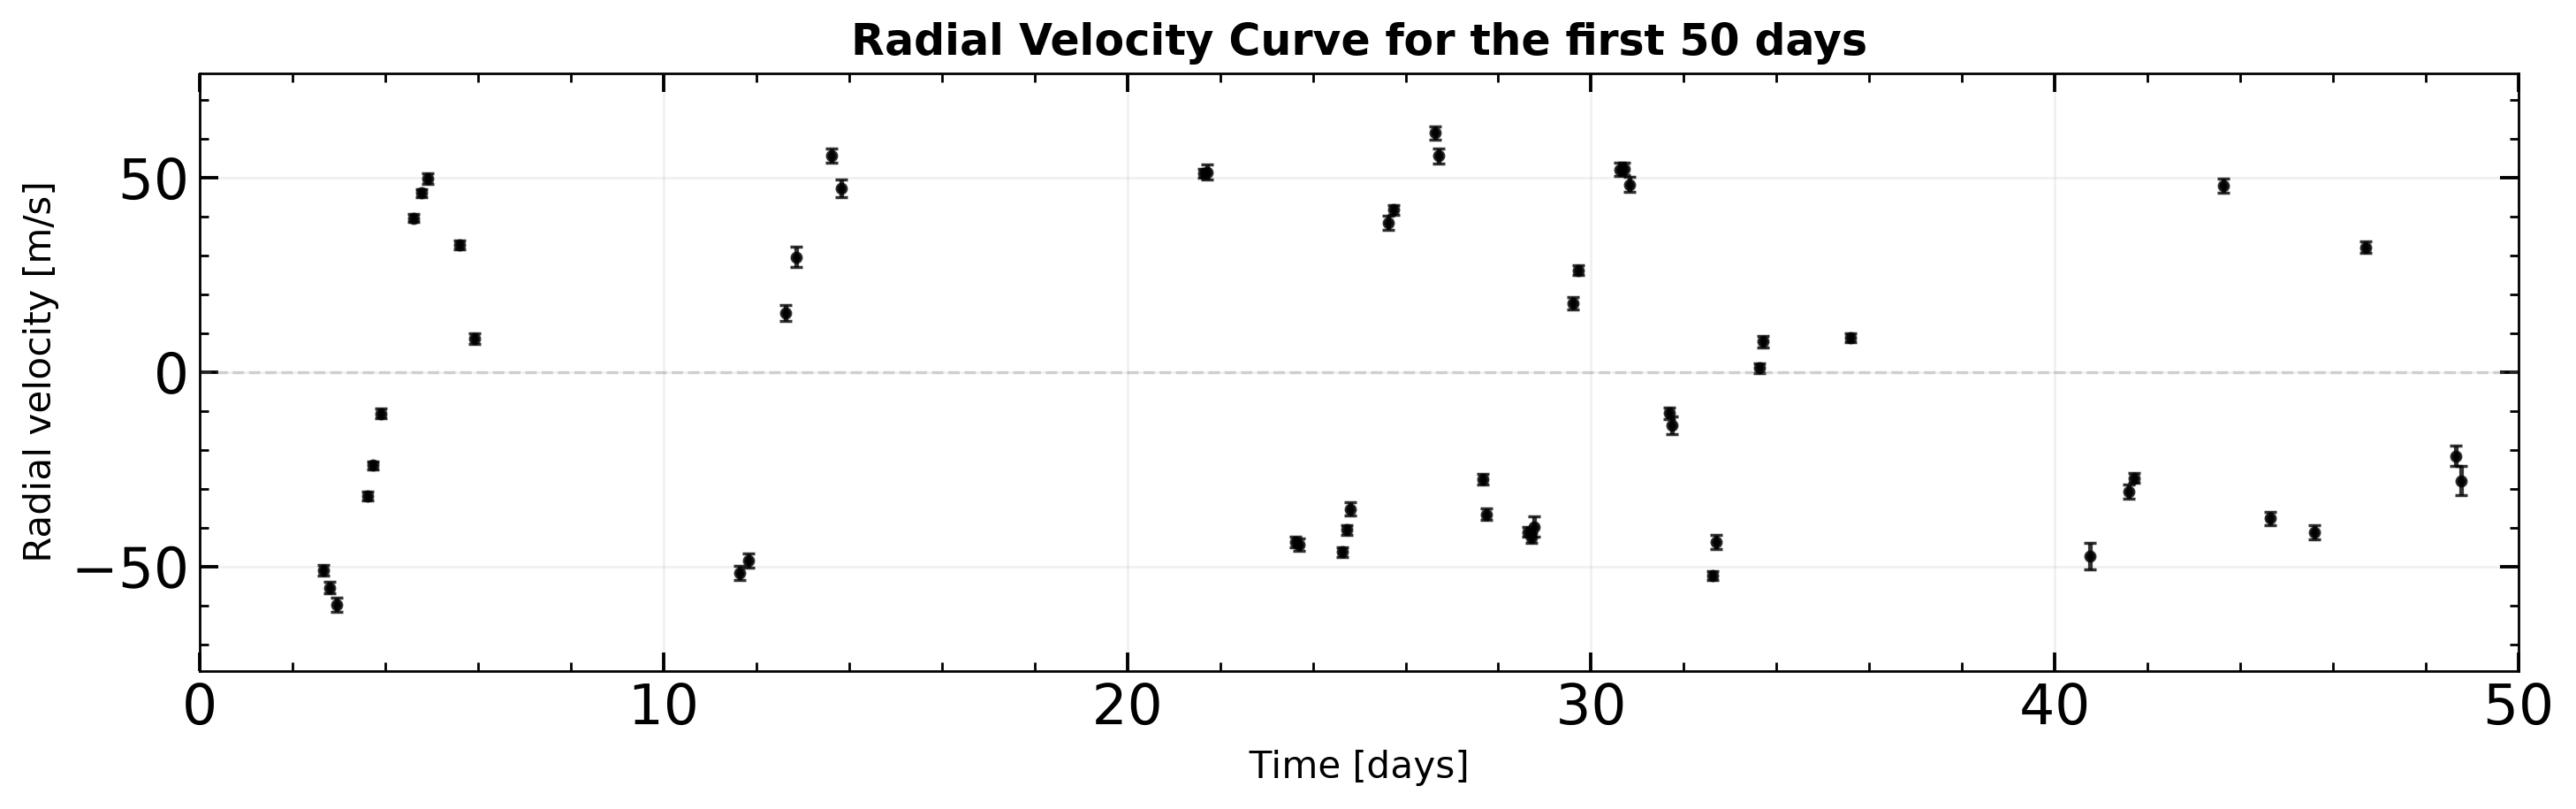

In [6]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=250)
ax.scatter(t50, v50, color="black", s = 1.0,zorder = 2)

# Error bars 
ax.errorbar(
    t50,
    v50,
    yerr=err50,
    fmt="o",
    ms=3.0,
    color='black',
    alpha=.8,
    capsize=2,
    #label="",
    #lw = 1
)
ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

ax.set_xlim(0, 50)
# make y-limits symmetric around zero
rv_absmax = max(abs(v50.min()), abs(v50.max()))
ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

# ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
# ax.legend(frameon=False, fontsize=9, loc="best")
ax.set_xlabel("Time [days]", fontsize=12)
ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
ax.set_title("Radial Velocity Curve for the first 50 days", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

For a circular orbit, the radial velocity will depend only on the period, phase, and semi-amplitude. This comes from the general equation
\begin{equation*}
    v_r(t) = K \bigg[ \cos{\big(\omega + \nu(t)\big)} + e\cos{\omega} \bigg] + v_{\rm sys}
\end{equation*}
reducing to 
\begin{equation*}
    \boxed{ v_r(t) = K \cos{\bigg(\frac{2\pi t}{P} + \phi \bigg)} }
\end{equation*}
when $e = 0, v_{\rm sys} = 0$

In [7]:
def RV(P, K, phi, t):
    return K * np.cos((2*np.pi*t)/(P) + phi)

In [8]:
# by eye guess of P K phi 
P_guess = 9.0            # days
K_guess = 50.0           # m/s
phi_guess = np.pi/2      # unitless

# fine time resolution for guess so that it's a smooth curve 
t_plot = np.linspace(0, 50, 2000)   # 2000 steps from 0 to 50 days

# guess curve 
v50guess = RV(P_guess, K_guess, phi_guess, t_plot)

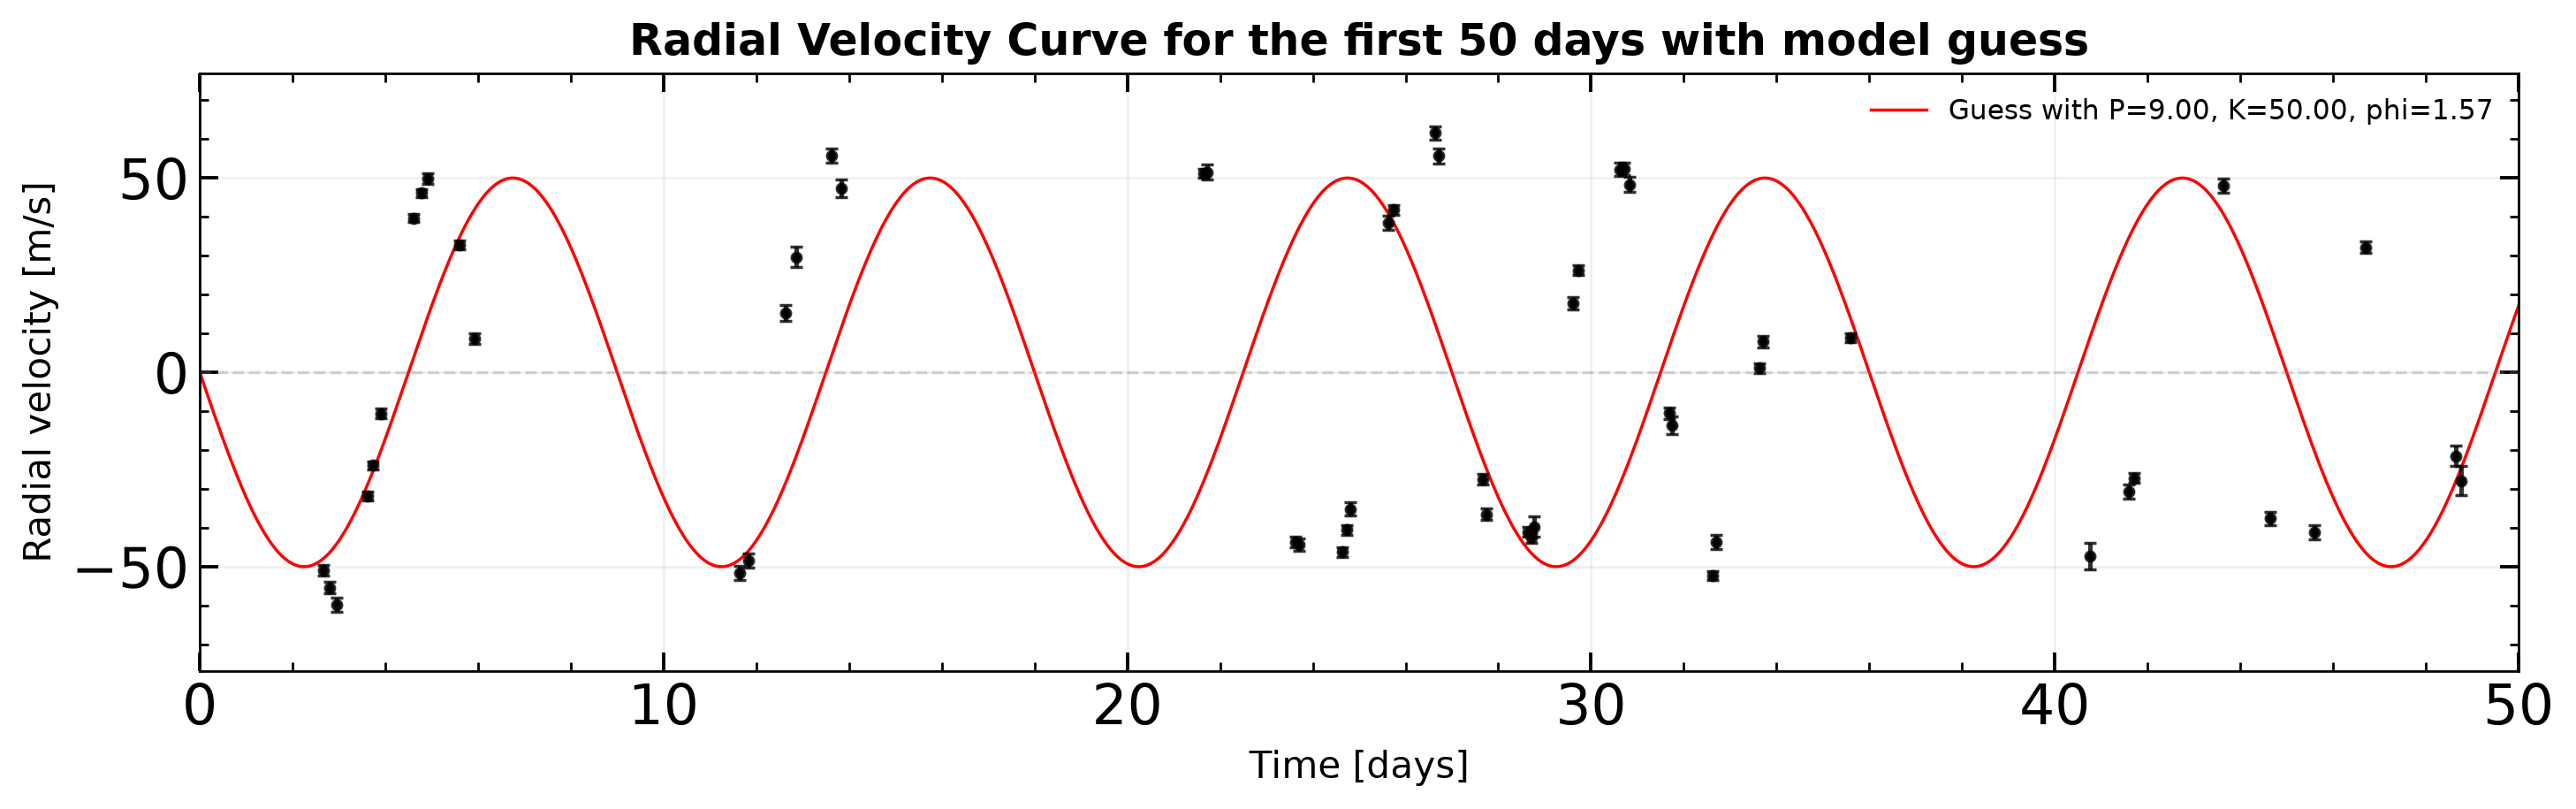

In [9]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=250)
ax.scatter(t50, v50, color="black", s = 1.0,zorder = 2)
ax.plot(t_plot, v50guess, color = "red", lw = 1, label = f"Guess with P={P_guess:.2f}, K={K_guess:.2f}, phi={phi_guess:.2f}")

# Error bars 
ax.errorbar(
    t50,
    v50,
    yerr=err50,
    fmt="o",
    ms=3.0,
    color='black',
    alpha=.8,
    capsize=2,
    #label="",
    #lw = 1
)
ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

ax.set_xlim(0, 50)
# make y-limits symmetric around zero
rv_absmax = max(abs(v50.min()), abs(v50.max()))
ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

# ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
ax.legend(frameon=False, fontsize=9, loc="best")
ax.set_xlabel("Time [days]", fontsize=12)
ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
ax.set_title("Radial Velocity Curve for the first 50 days with model guess", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

looks like an 'OK' fit, but for sure doesn't look like it sthe right answer just yet. 

### Over all the data now

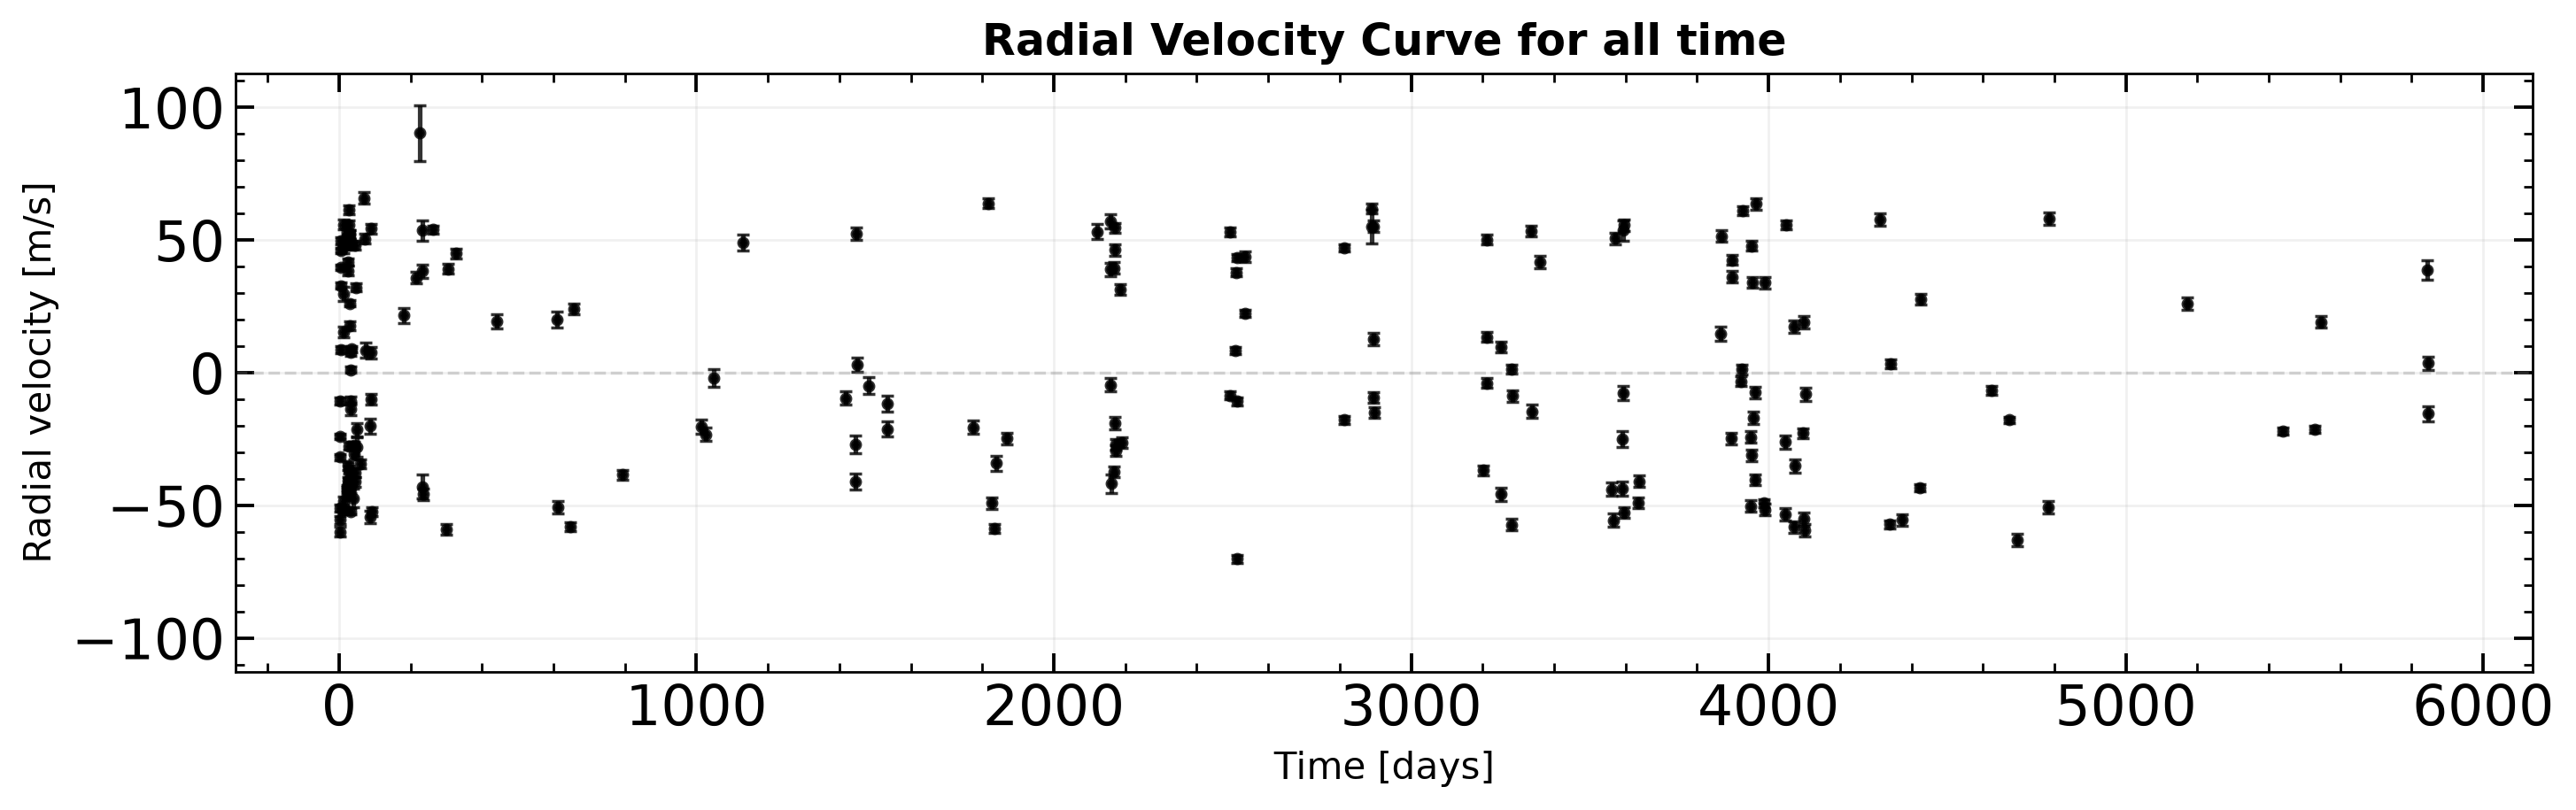

In [10]:
# all-time
fig, ax = plt.subplots(figsize=(12, 4), dpi=250)
ax.scatter(time, v, color="black", s = 1.0,zorder = 2)

# Error bars 
ax.errorbar(
    time,
    v,
    yerr=err,
    fmt="o",
    ms=3.0,
    color='black',
    alpha=.8,
    capsize=2,
    #label="",
    #lw = 1
)
ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

# ax.set_xlim(0, 6000)
# make y-limits symmetric around zero
rv_absmax = max(abs(v.min()), abs(v.max()))
ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

# ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
# ax.legend(frameon=False, fontsize=9, loc="best")
ax.set_xlabel("Time [days]", fontsize=12)
ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
ax.set_title("Radial Velocity Curve for all time", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

In [11]:
# by eye guess of P K phi 
P_guess = 9.0            # days
K_guess = 50.0           # m/s
phi_guess = np.pi/2      # unitless

# fine time resolution for guess so that it's a smooth curve 
t_plot = np.linspace(0, 6000, 20000)   # 20000 steps from 0 to 6000 days

# guess curve 
vguess = RV(P_guess, K_guess, phi_guess, t_plot)

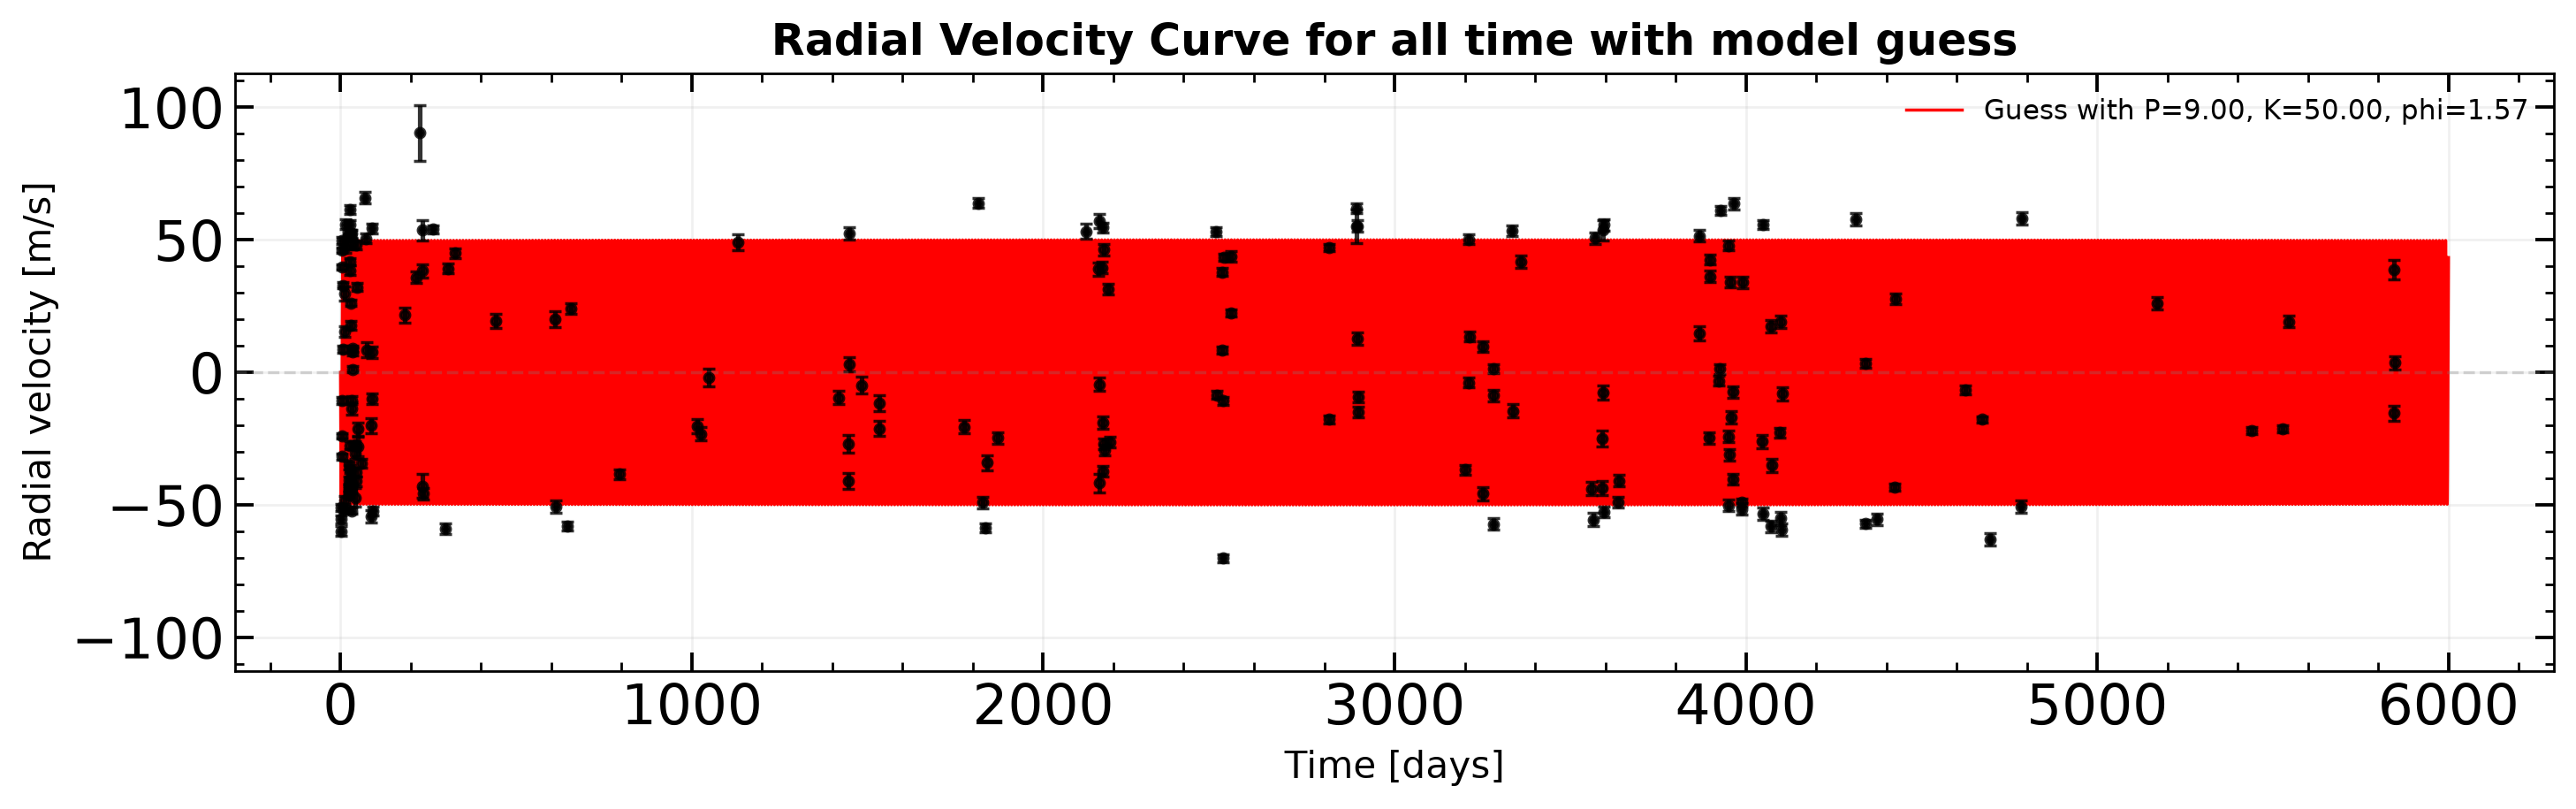

In [12]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=250)
ax.scatter(time, v, color="black", s = 1.0,zorder = 2)
ax.plot(t_plot, vguess, color = "red", lw = 1, label = f"Guess with P={P_guess:.2f}, K={K_guess:.2f}, phi={phi_guess:.2f}")

# Error bars 
ax.errorbar(
    time,
    v,
    yerr=err,
    fmt="o",
    ms=3.0,
    color='black',
    alpha=.8,
    capsize=2,
    #label="",
    #lw = 1
)
ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

# ax.set_xlim(0, 6000)
# make y-limits symmetric around zero
rv_absmax = max(abs(v.min()), abs(v.max()))
ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

# ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
ax.legend(frameon=False, fontsize=9, loc="best")
ax.set_xlabel("Time [days]", fontsize=12)
ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
ax.set_title("Radial Velocity Curve for all time with model guess", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

looks terrible, the period must be longer? 

Actually, this isn't right. I can't just make P larger since then it won't match the first 50 days. I think this is why we were given the 50 days windows at the start so let me use those and see. 

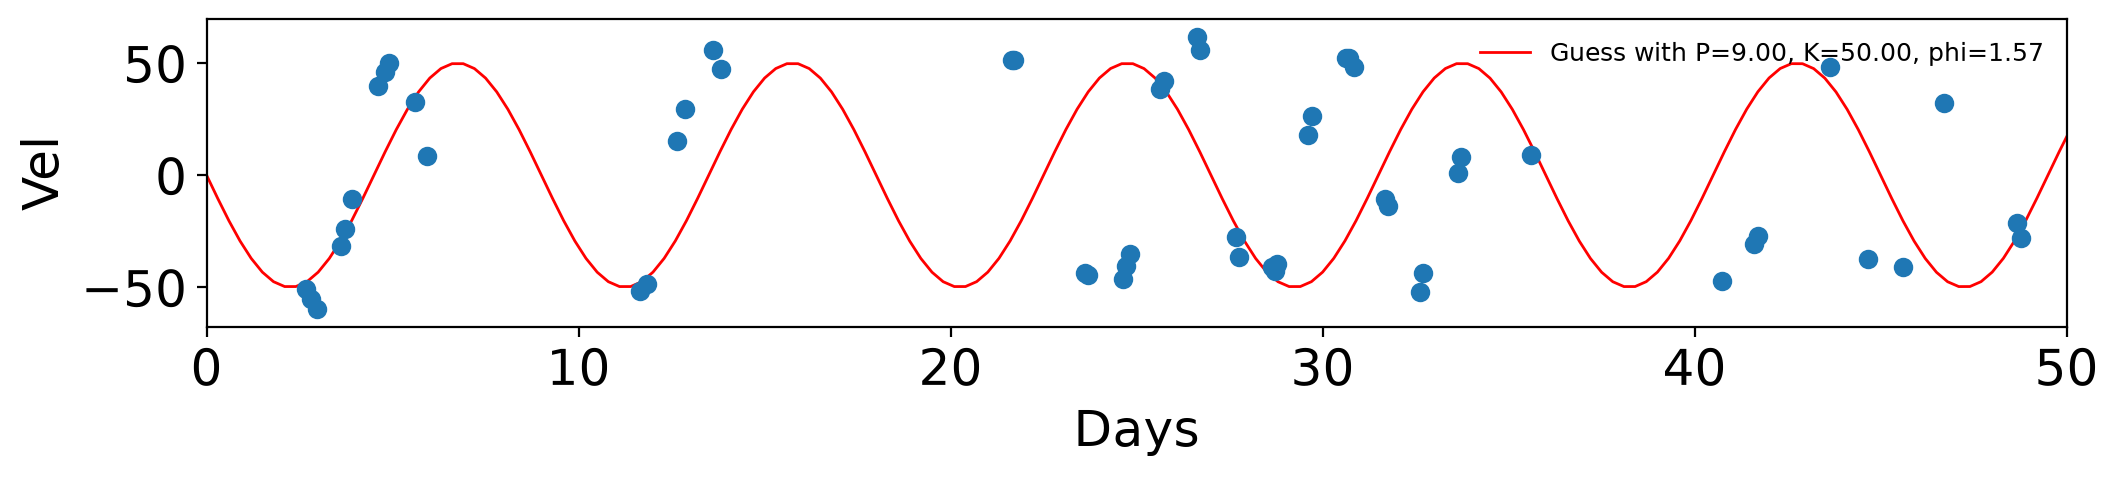

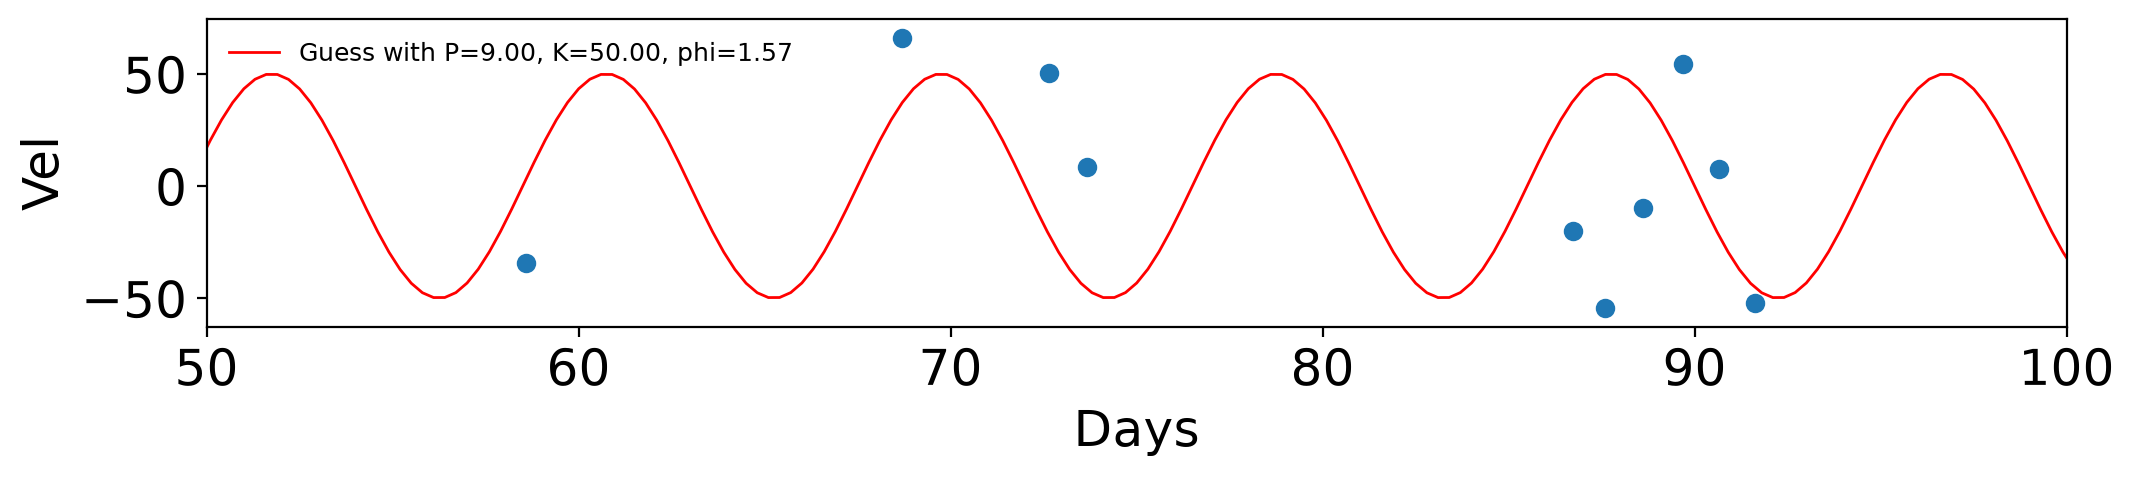

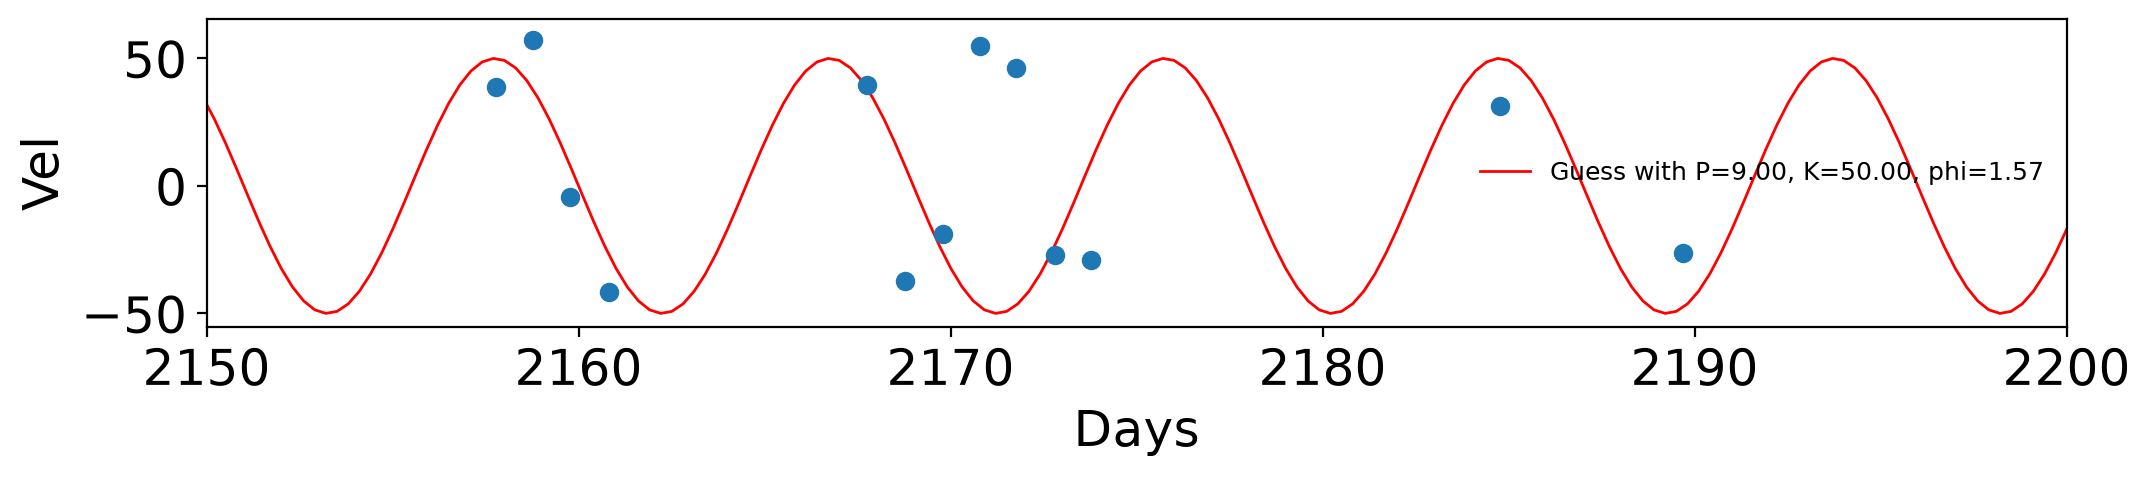

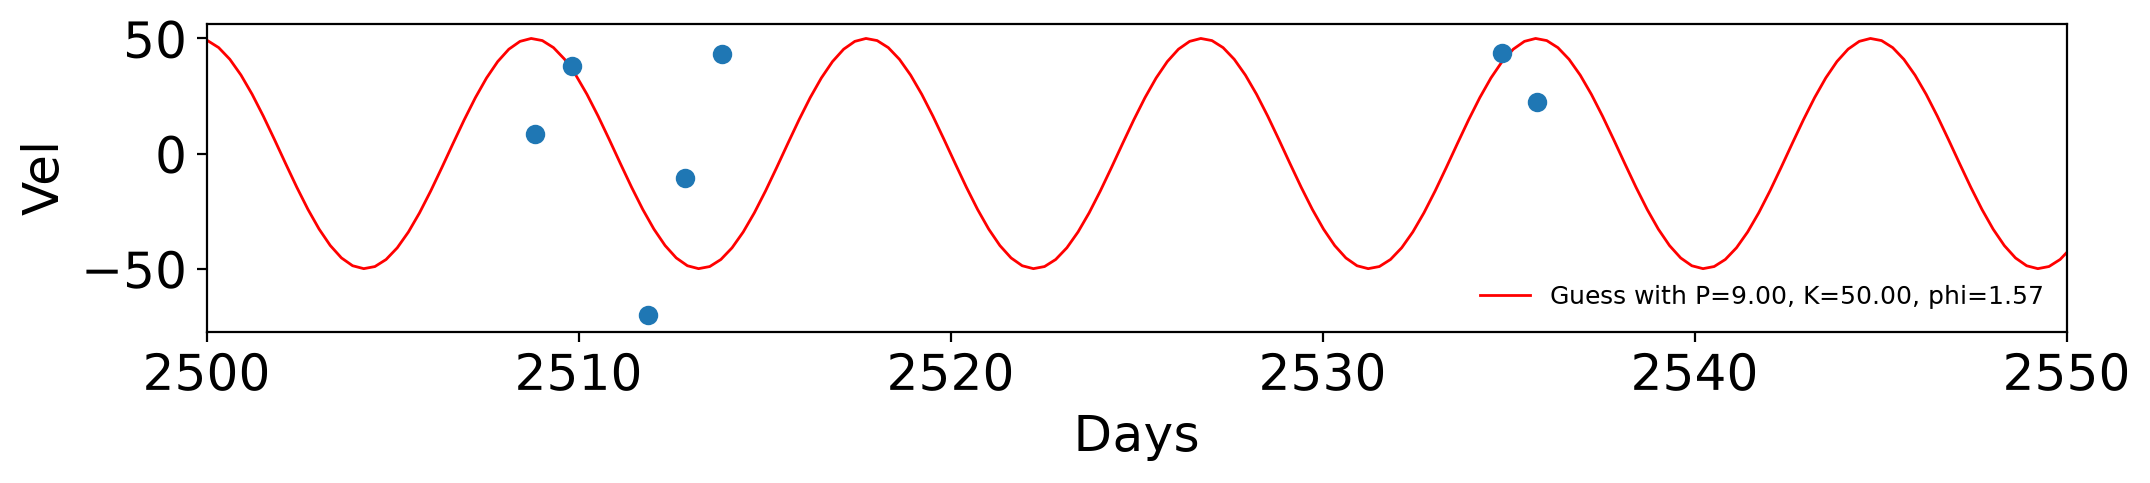

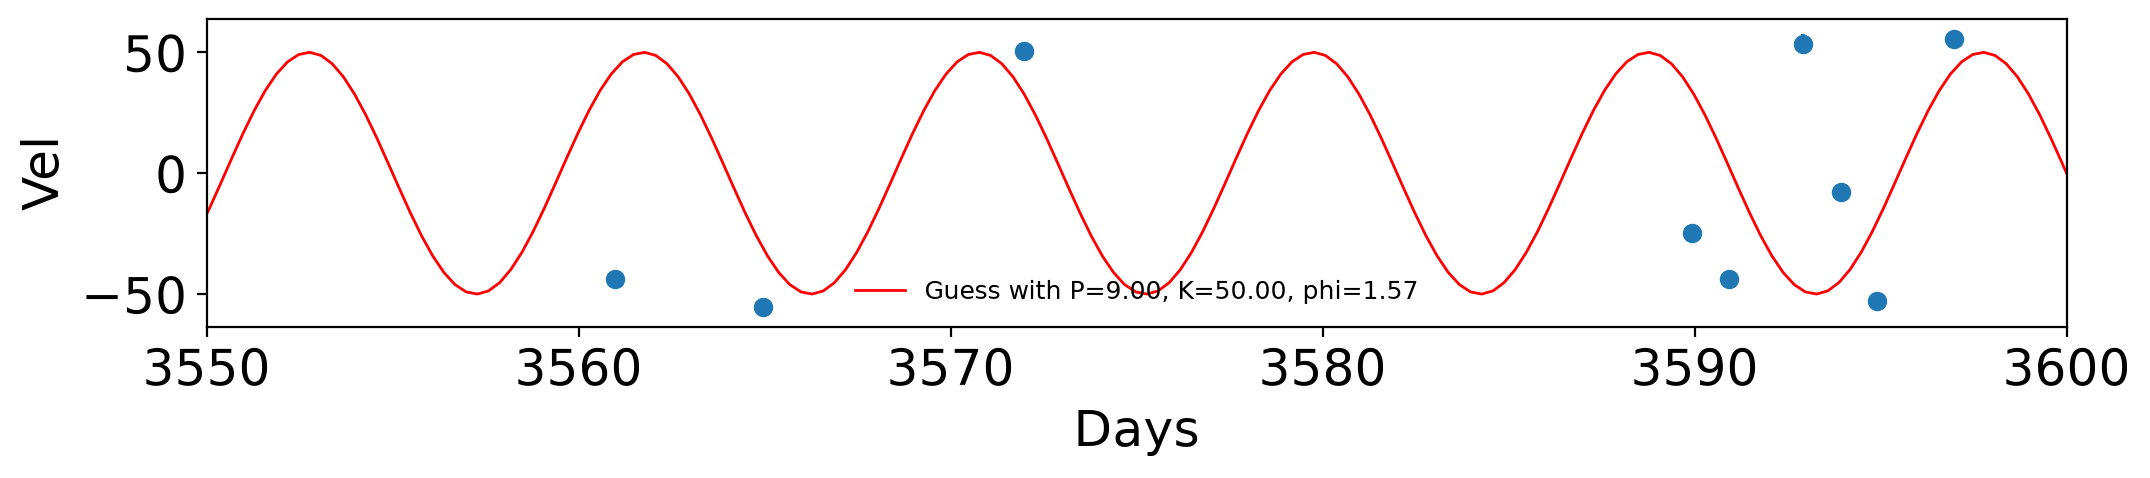

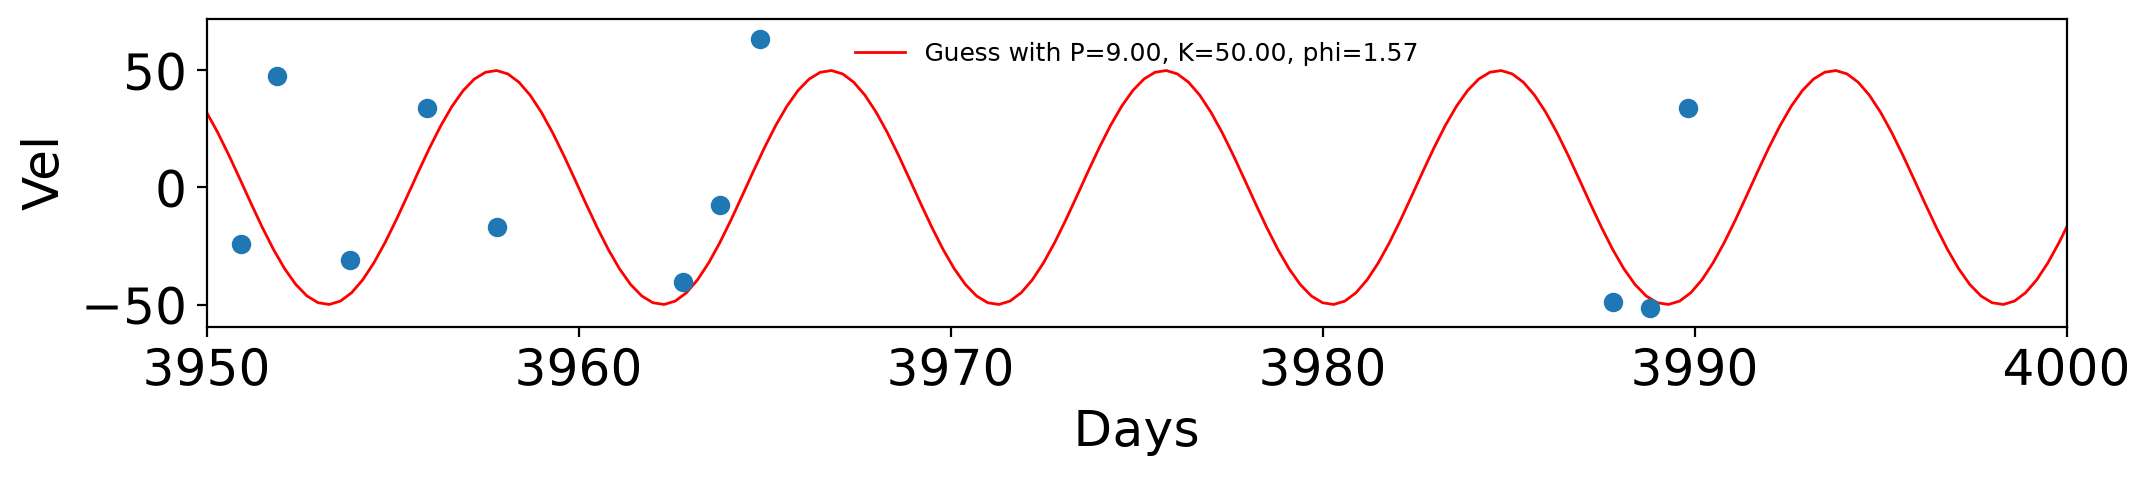

In [13]:
# Using the given plotting scripts

step = 50
for i,start in enumerate(np.arange(0, 6000, step)):
    end = start + step
    sel = np.logical_and(time > start, time < end)
    
    # Only plot the figure if there are a reasonable number of points in the range
    if len(time[sel]) > 6:
        fig = plt.figure(num=i, figsize=[12.,2.], dpi=200)
        plt.errorbar(time[sel],v[sel],err[sel],marker='o',ls='')
        plt.xlim((start,start+50))
        plt.xlabel("Days")
        plt.ylabel("Vel")

        # Add my guess model to the plots
        plt.plot(t_plot, vguess, color = "red", lw = 1, label = f"Guess with P={P_guess:.2f}, K={K_guess:.2f}, phi={phi_guess:.2f}")
        plt.legend(frameon=False, fontsize=9, loc="best")

I'd like to format it the same way I did above: 

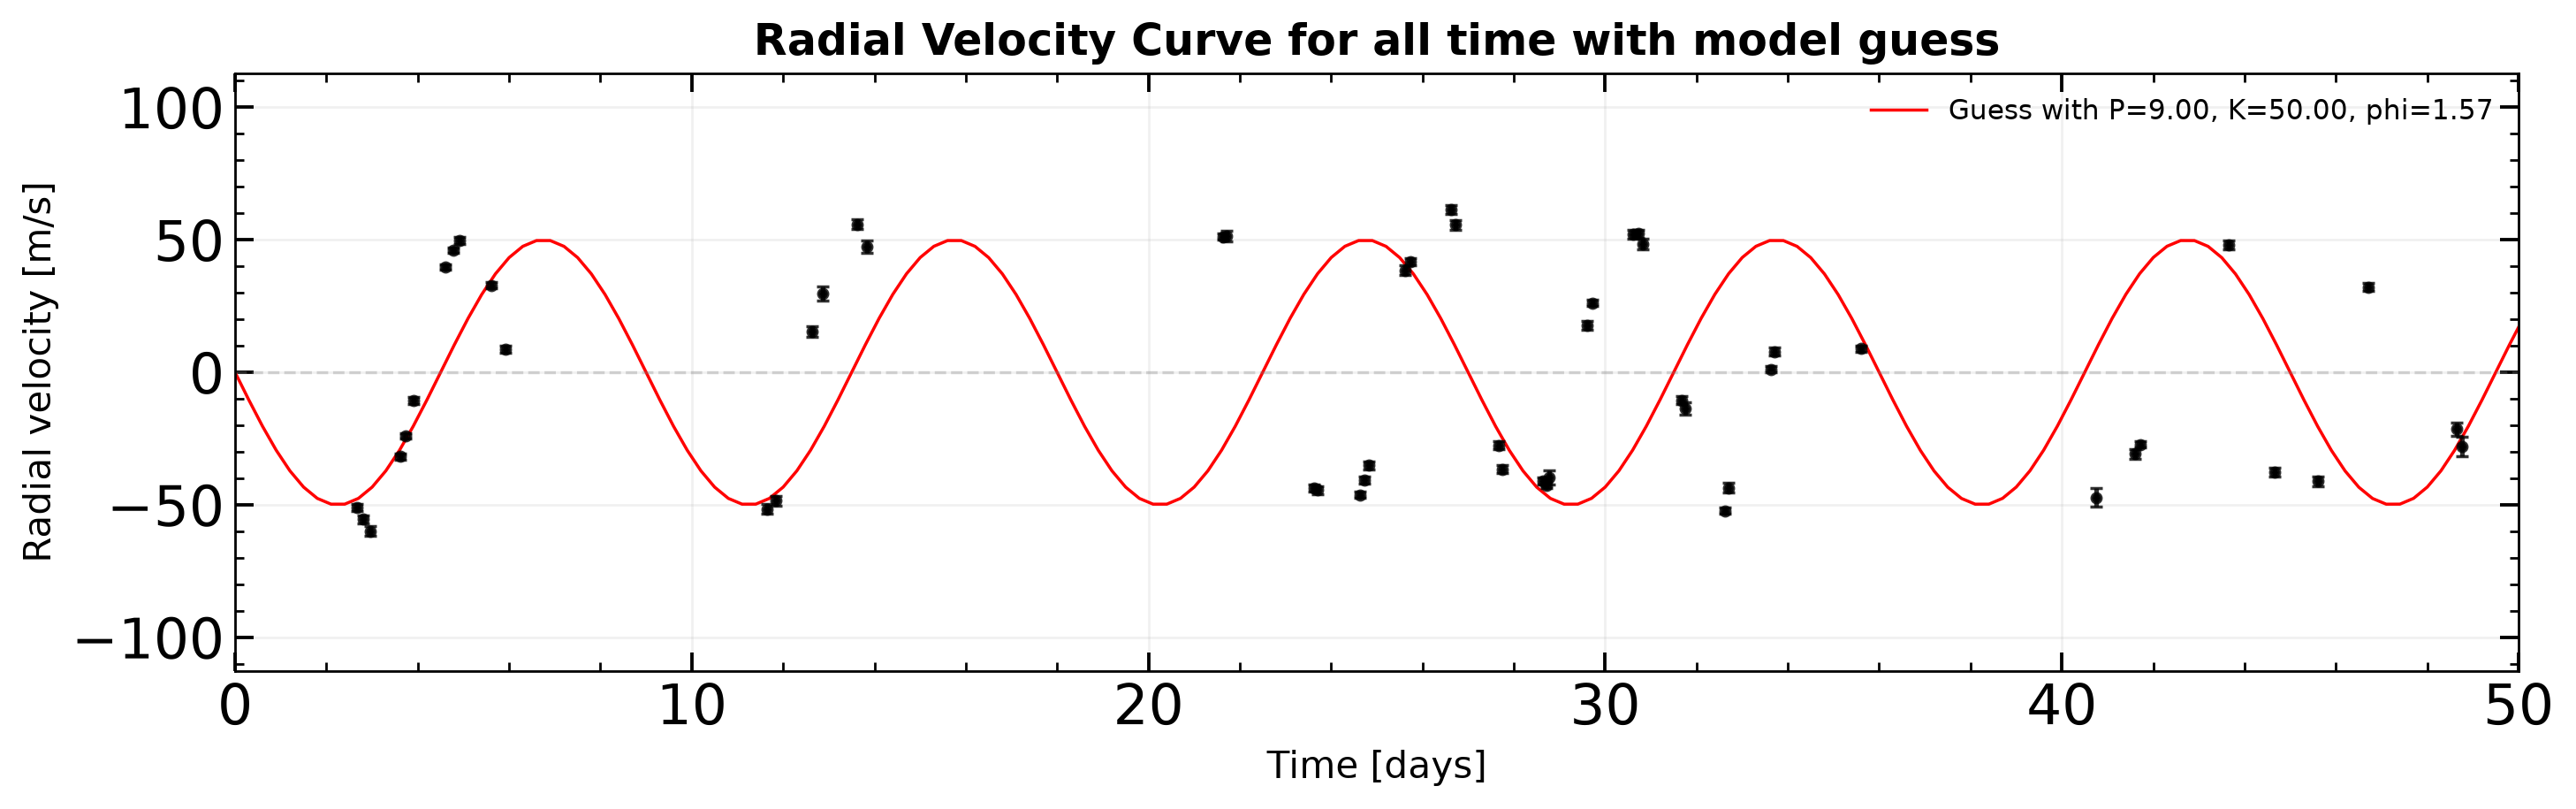

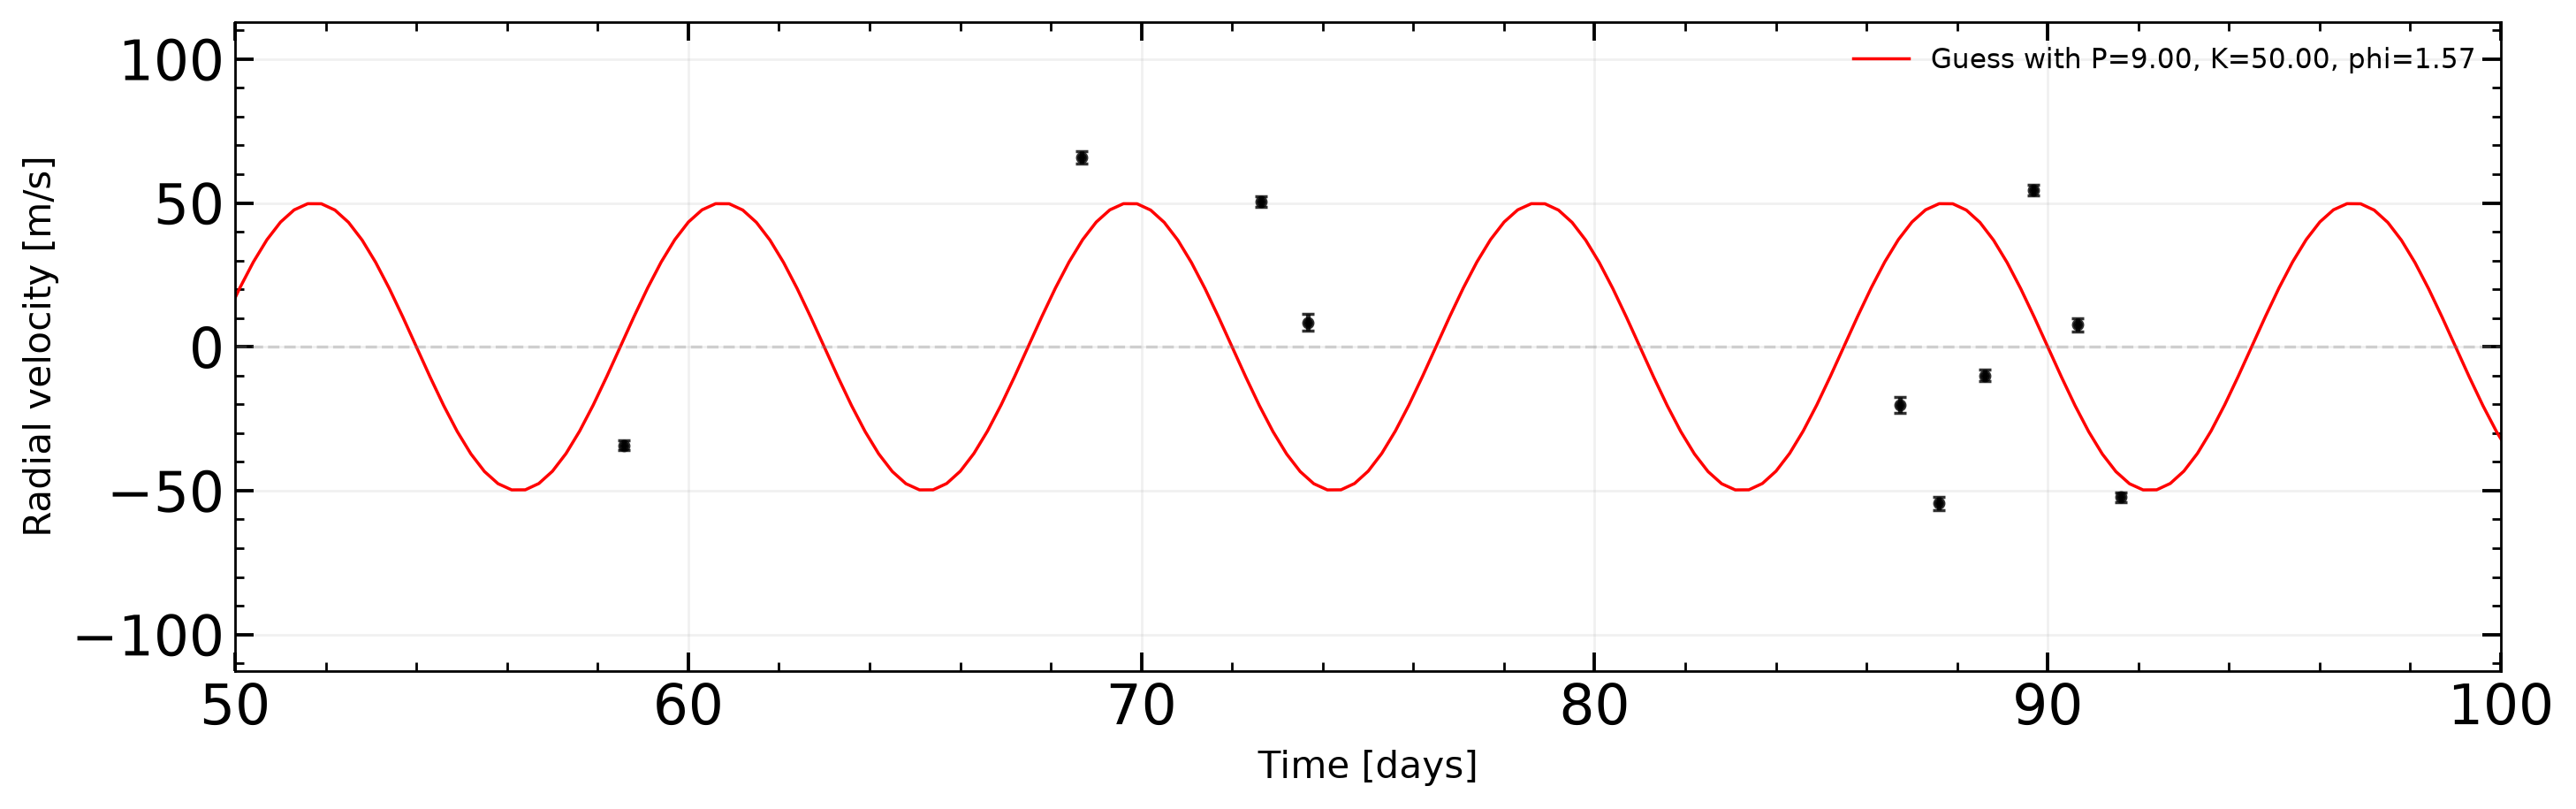

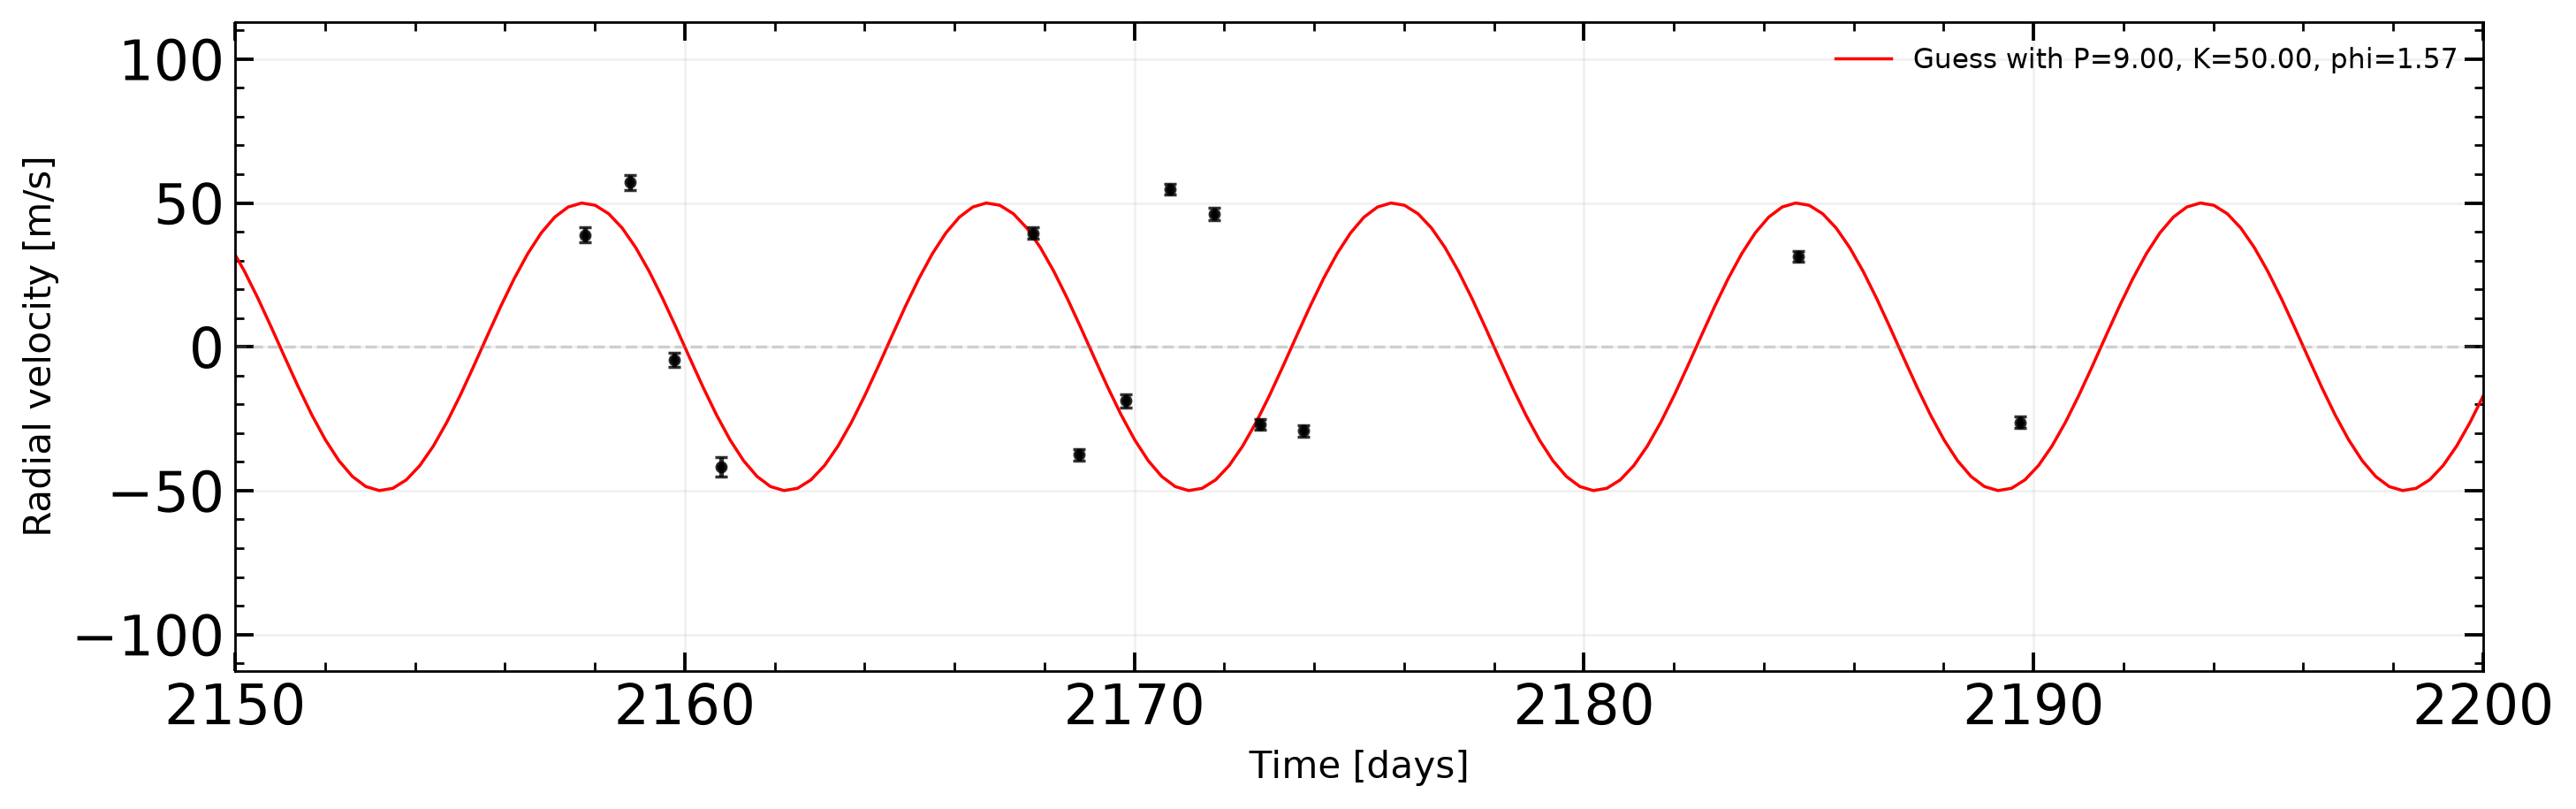

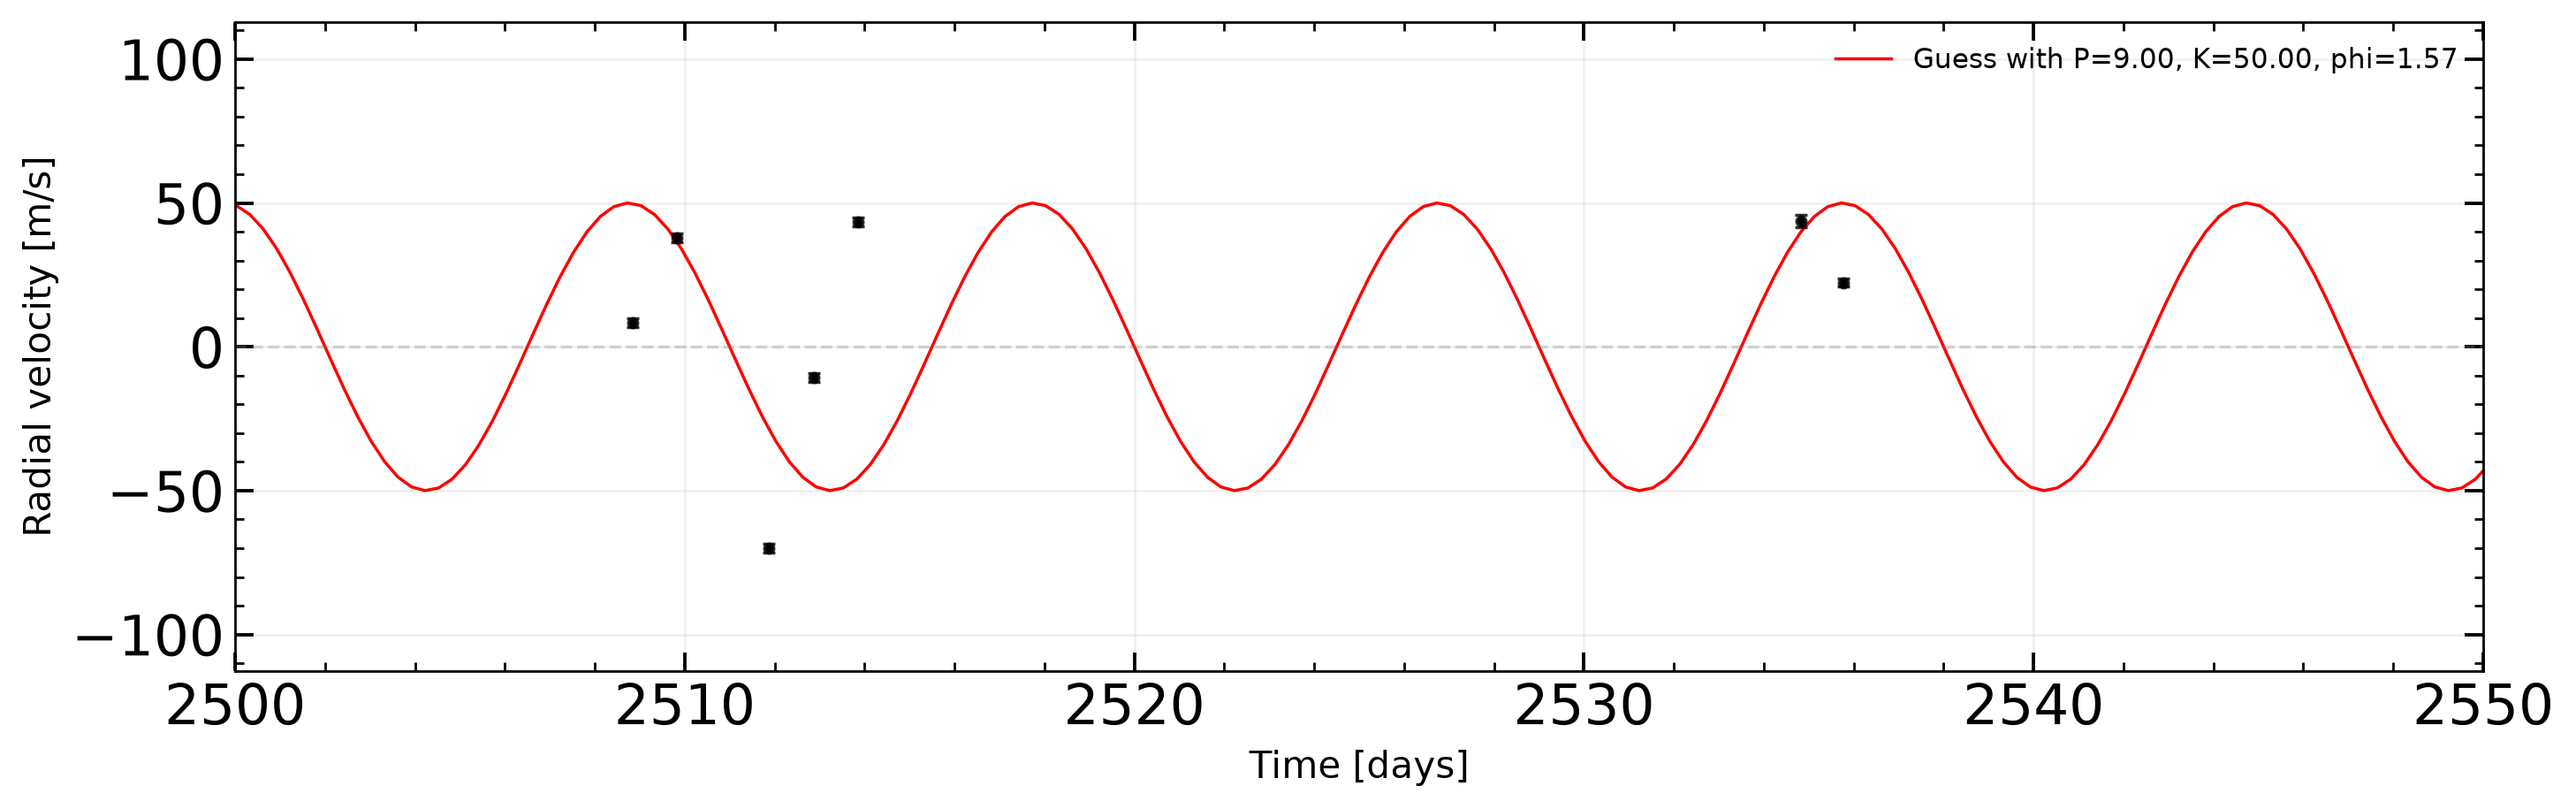

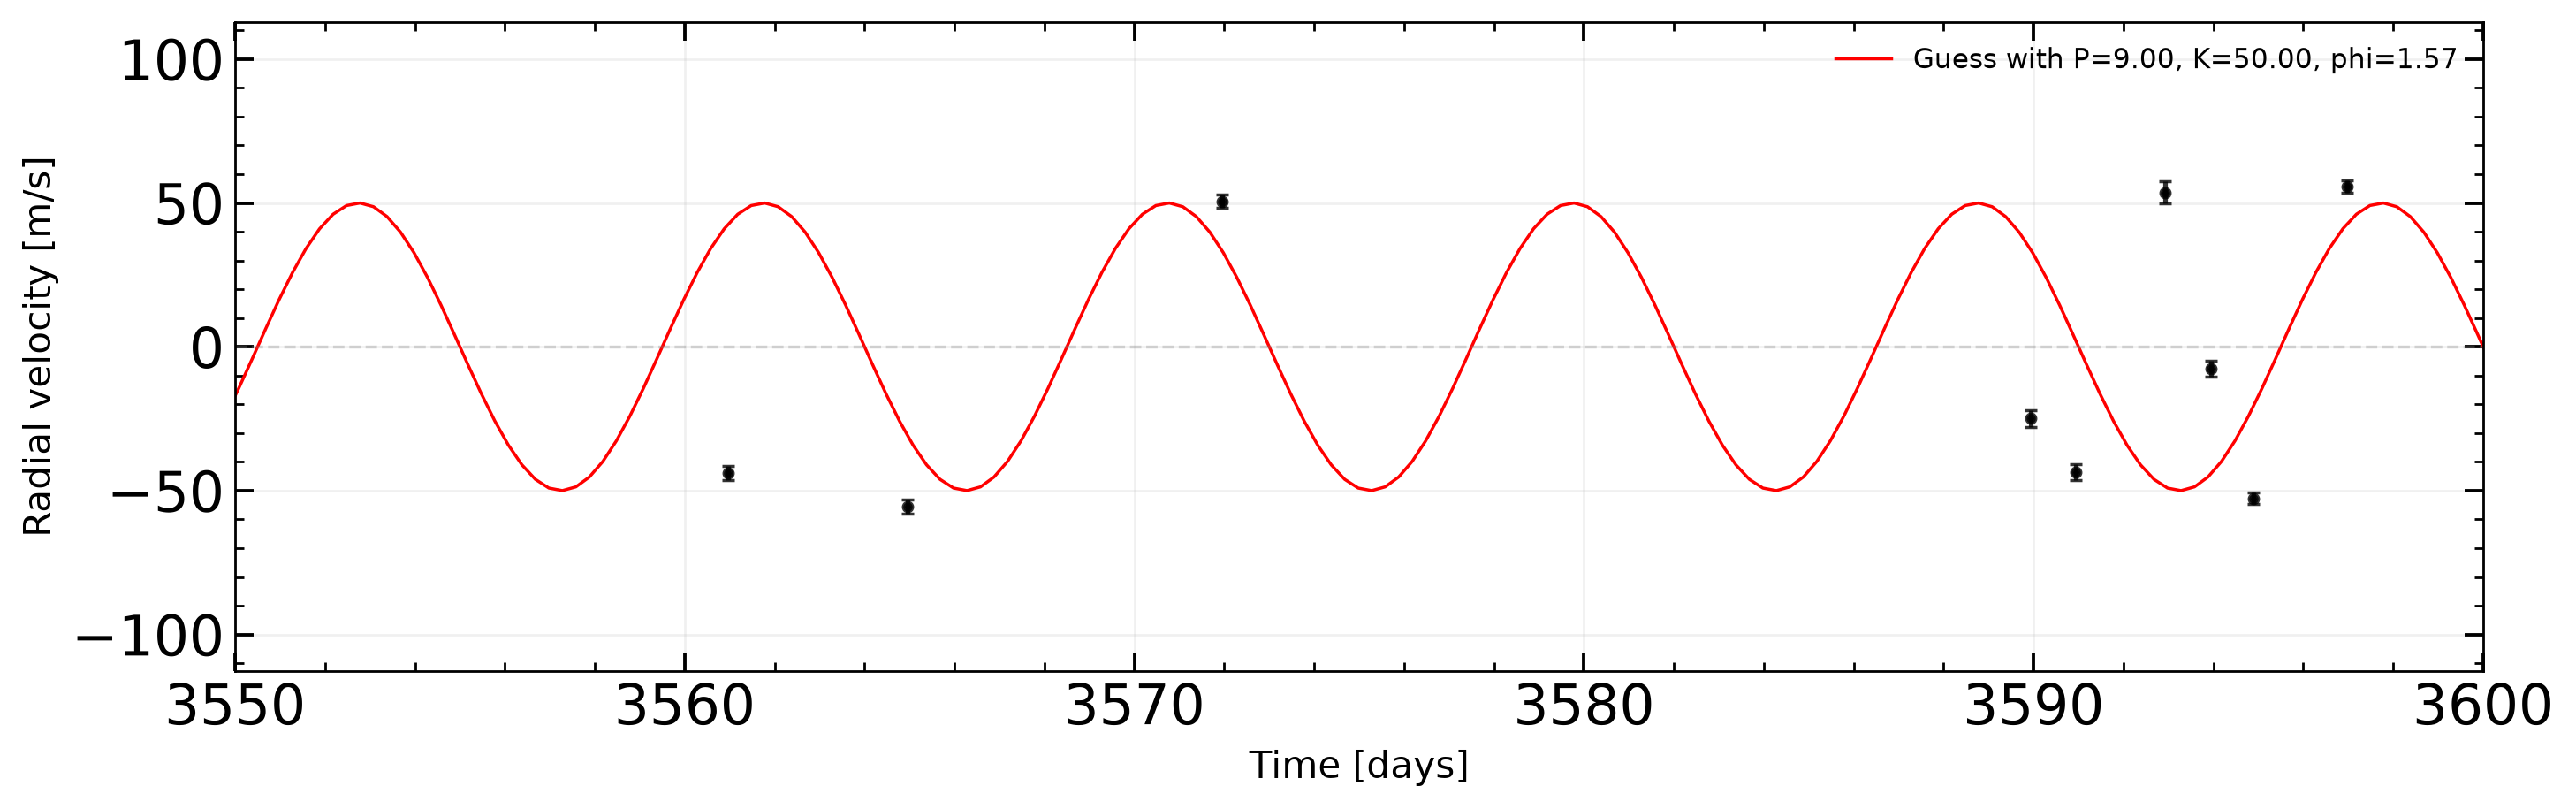

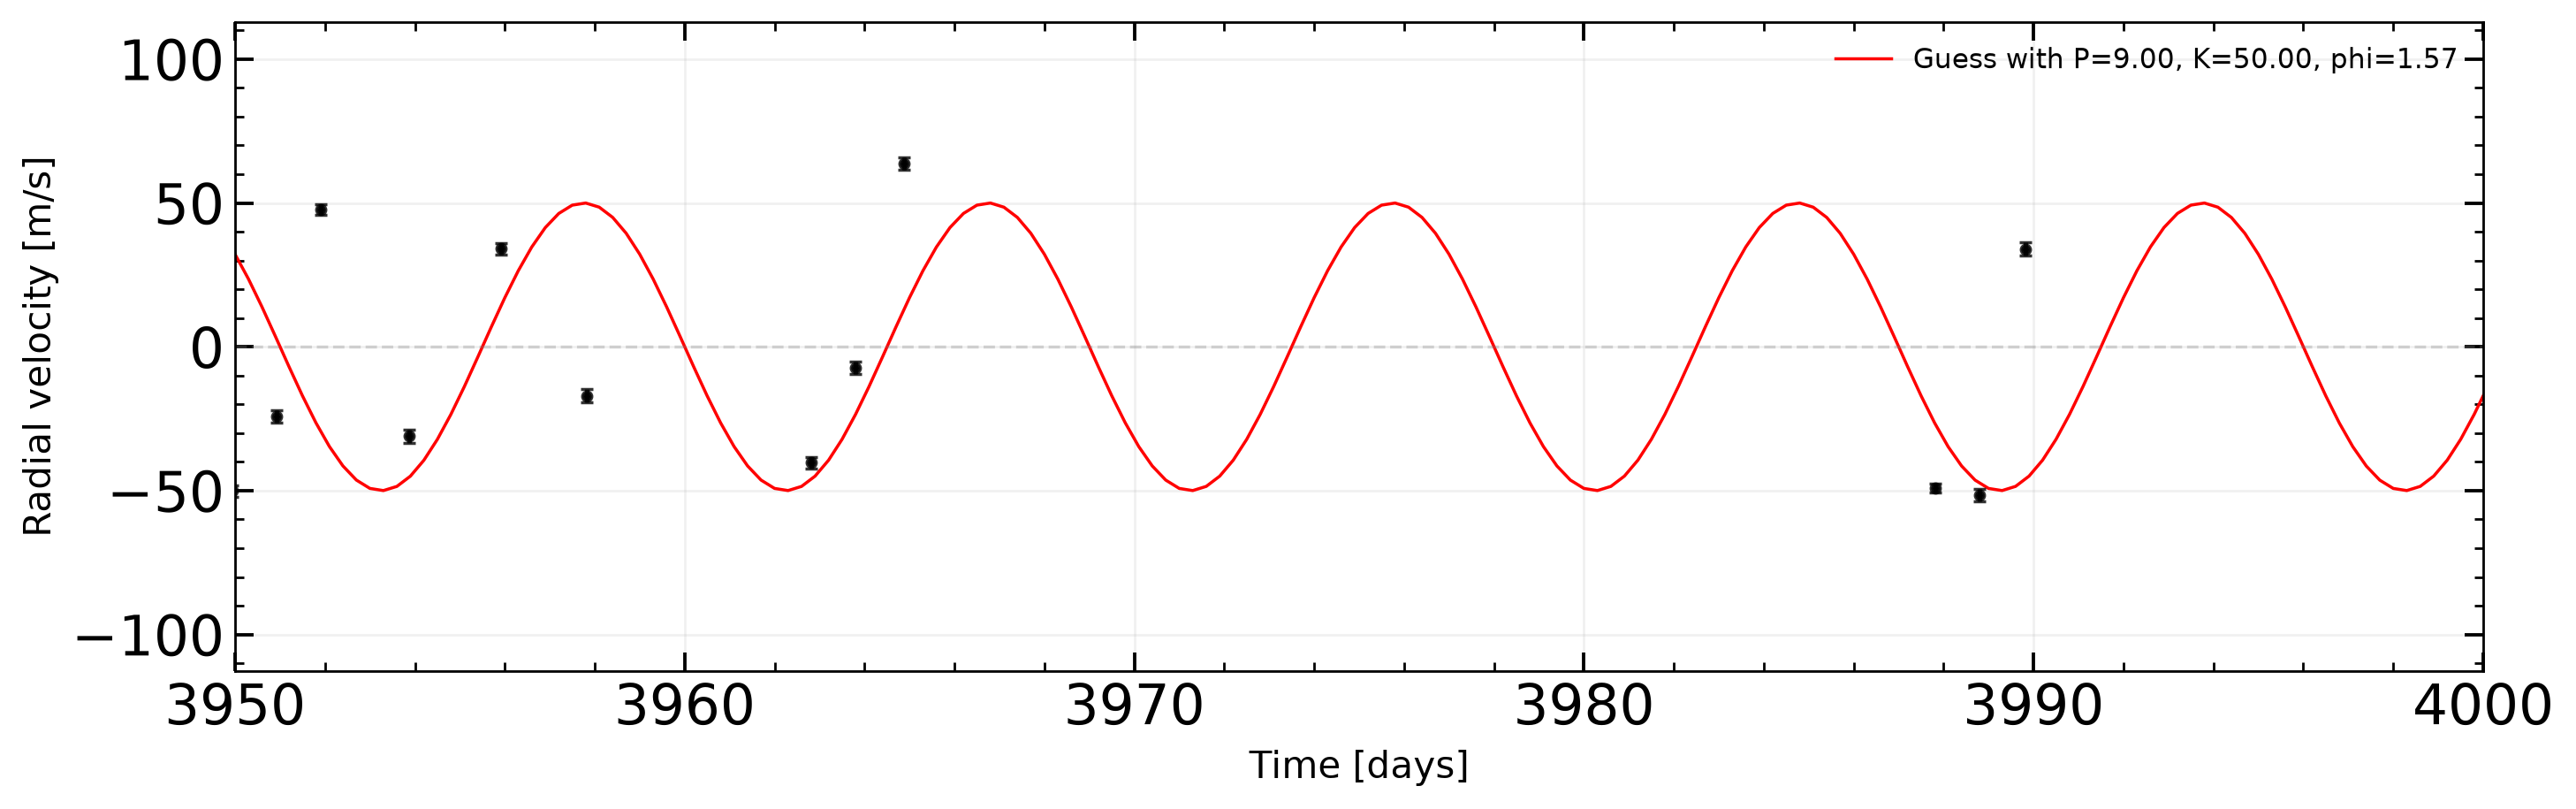

In [14]:
# Using the given plotting scripts but with my formatting

step = 50
for i,start in enumerate(np.arange(0, 6000, step)):
    end = start + step
    sel = np.logical_and(time > start, time < end)
    
    # Only plot the figure if there are a reasonable number of points in the range
    if len(time[sel]) > 6:
        # fig = plt.figure(num=i, figsize=[12.,2.], dpi=200)
        # plt.errorbar(time[sel],v[sel],err[sel],marker='o',ls='')
        # plt.xlim((start,start+50))
        # plt.xlabel("Days")
        # plt.ylabel("Vel")

        fig, ax = plt.subplots(num = i, figsize=(12, 4), dpi=250)
        ax.scatter(time, v, color="black", s = 1.0,zorder = 2)
        ax.plot(t_plot, vguess, color = "red", lw = 1, label = f"Guess with P={P_guess:.2f}, K={K_guess:.2f}, phi={phi_guess:.2f}")

        # Error bars 
        ax.errorbar(
            time,
            v,
            yerr=err,
            fmt="o",
            ms=3.0,
            color='black',
            alpha=.8,
            capsize=2,
            #label="",
            #lw = 1
        )
        ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

        ax.set_xlim((start,start+50))
        # make y-limits symmetric around zero
        rv_absmax = max(abs(v.min()), abs(v.max()))
        ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

        # ticks on all four sides
        ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
        ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
        ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax.grid(True, which="major", alpha=0.18, lw=0.8)
        ax.legend(frameon=False, fontsize=9, loc="best")
        ax.set_xlabel("Time [days]", fontsize=12)
        ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
        ax.set_title("Radial Velocity Curve for all time with model guess", fontsize=14, fontweight="bold") if i==0 else ax.set_title("")
        fig.tight_layout()

Looks better than the plot with the bright red band since we're only zooming in on the parts with the most data points. The fit seems okay but without any quantitative analysis I can't really pin down how good/bad it truly is. 

### Phase folding the data

In [15]:
# params
P = 9.0             # days 
K = 50              # m/s 
phi = np.pi/2       # unitless

# phase folding 
t_fold = time % P 

# Model line 
t_model = np.linspace(0, P, 5000)            # from 0 to P in 5000 steps 
v_model = RV(P, K, phi, t_model)

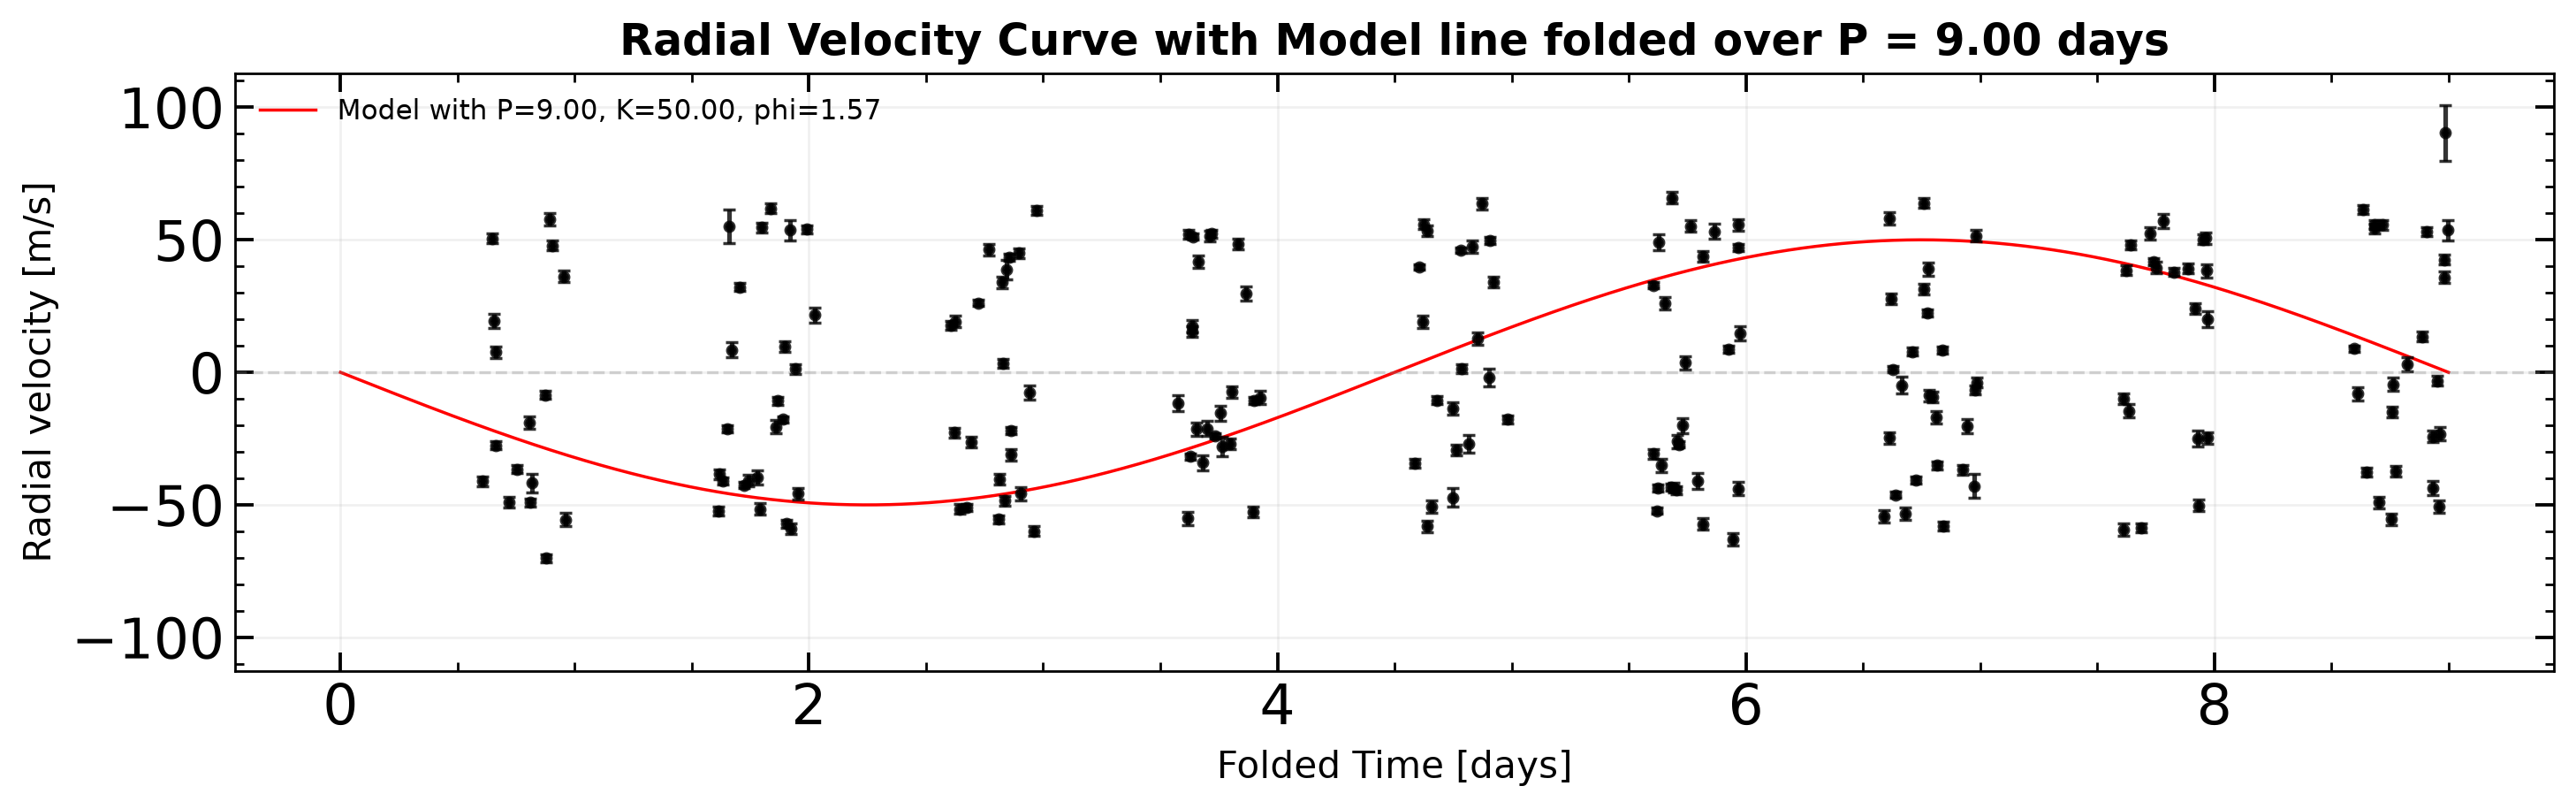

In [16]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=250)
ax.scatter(t_fold, v, color="black", s = 1.0,zorder = 2)
ax.plot(t_model, v_model, color = "red", lw = 1, label = f"Model with P={P:.2f}, K={K:.2f}, phi={phi:.2f}")

# Error bars 
ax.errorbar(
    t_fold,
    v,
    yerr=err,
    fmt="o",
    ms=3.0,
    color='black',
    alpha=.8,
    capsize=2,
    #label="",
    #lw = 1
)
ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

# ax.set_xlim(0, P)
# make y-limits symmetric around zero
rv_absmax = max(abs(v.min()), abs(v.max()))
ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

# ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
ax.legend(frameon=False, fontsize=9, loc="best")
ax.set_xlabel("Folded Time [days]", fontsize=12)
ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
ax.set_title(f"Radial Velocity Curve with Model line folded over P = {P:.2f} days", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

From the folded data I can tell I need to adjust my parameters:

In [24]:
# params
P = 2.0            # days 
K = 60.0              # m/s 
phi = np.pi/3       # unitless

# phase folding 
t_fold = time % P 

# Model line 
t_model = np.linspace(0, P, 5000)            # from 0 to P in 5000 steps 
v_model = RV(P, K, phi, t_model)

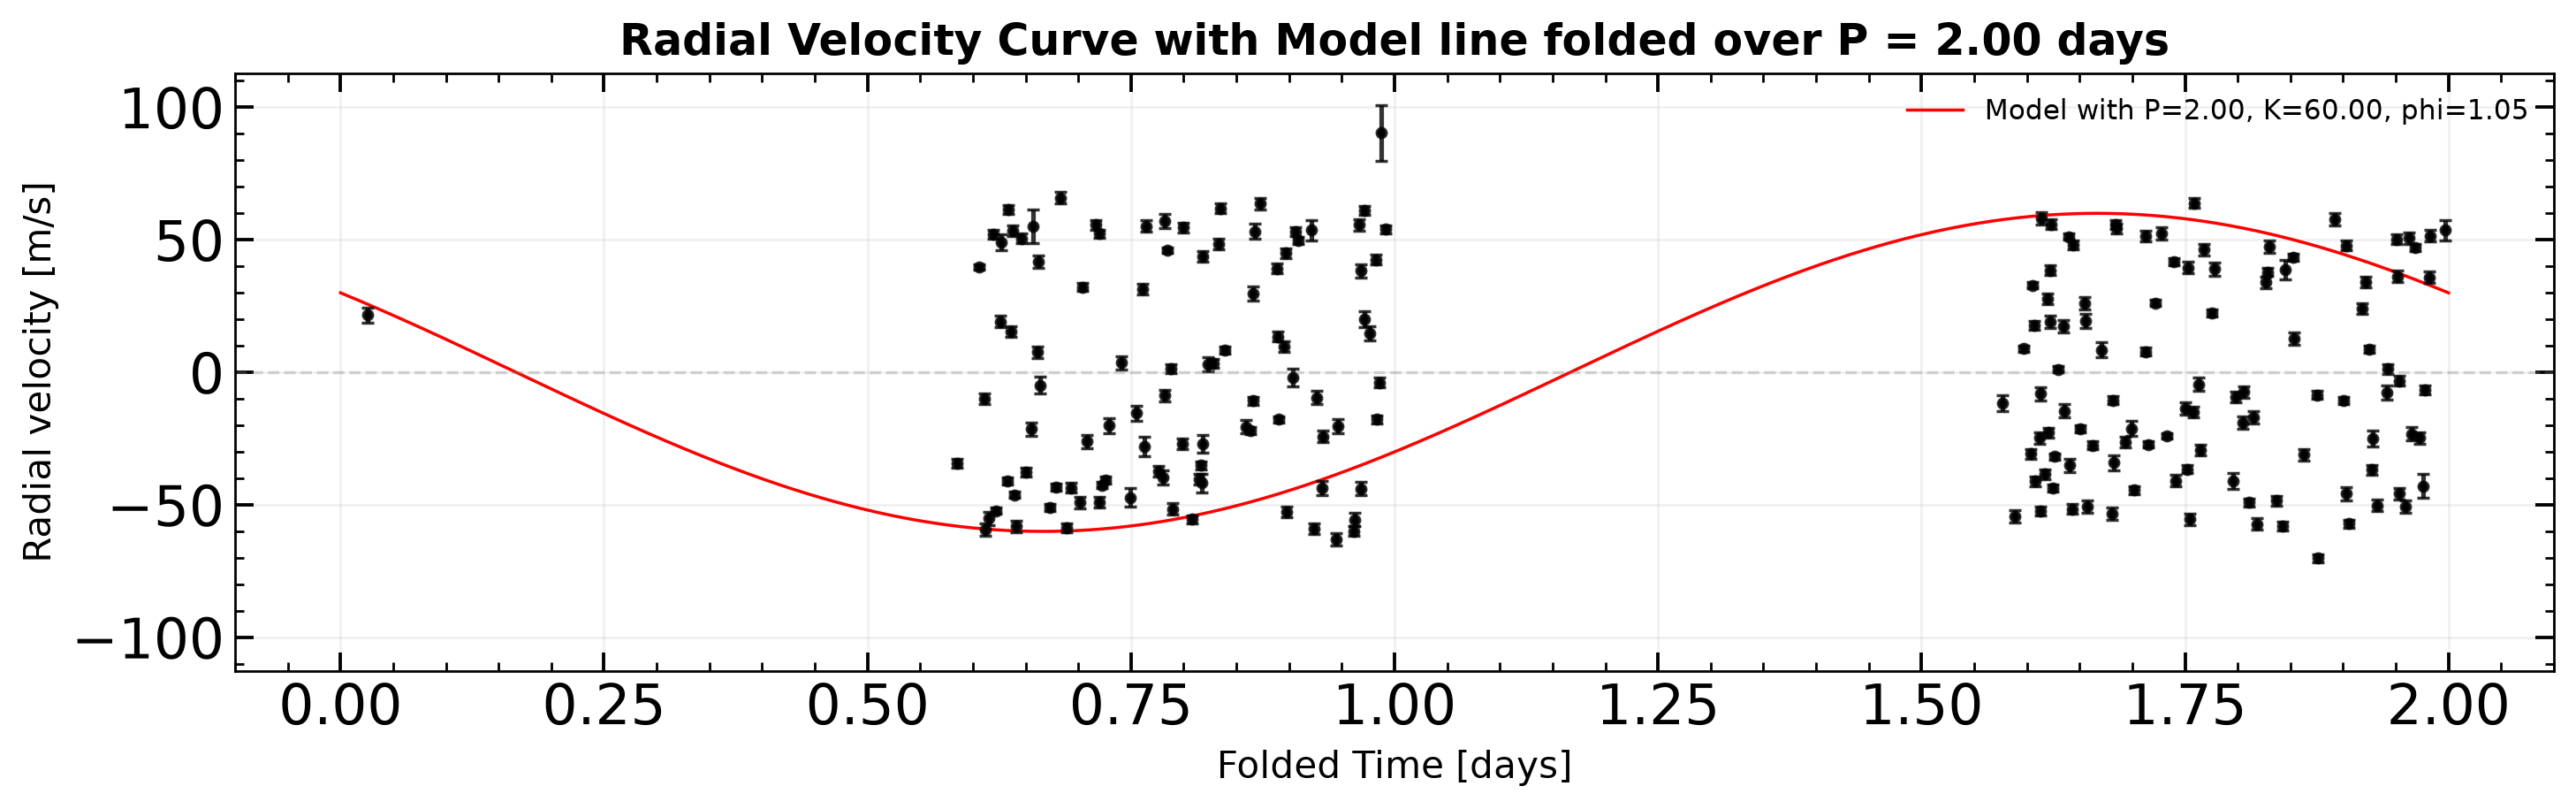

In [25]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=250)
ax.scatter(t_fold, v, color="black", s = 1.0,zorder = 2)
ax.plot(t_model, v_model, color = "red", lw = 1, label = f"Model with P={P:.2f}, K={K:.2f}, phi={phi:.2f}")

# Error bars 
ax.errorbar(
    t_fold,
    v,
    yerr=err,
    fmt="o",
    ms=3.0,
    color='black',
    alpha=.8,
    capsize=2,
    #label="",
    #lw = 1
)
ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

# ax.set_xlim(0, P)
# make y-limits symmetric around zero
rv_absmax = max(abs(v.min()), abs(v.max()))
ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

# ticks on all four sides
ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.grid(True, which="major", alpha=0.18, lw=0.8)
ax.legend(frameon=False, fontsize=9, loc="best")
ax.set_xlabel("Folded Time [days]", fontsize=12)
ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
ax.set_title(f"Radial Velocity Curve with Model line folded over P = {P:.2f} days", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

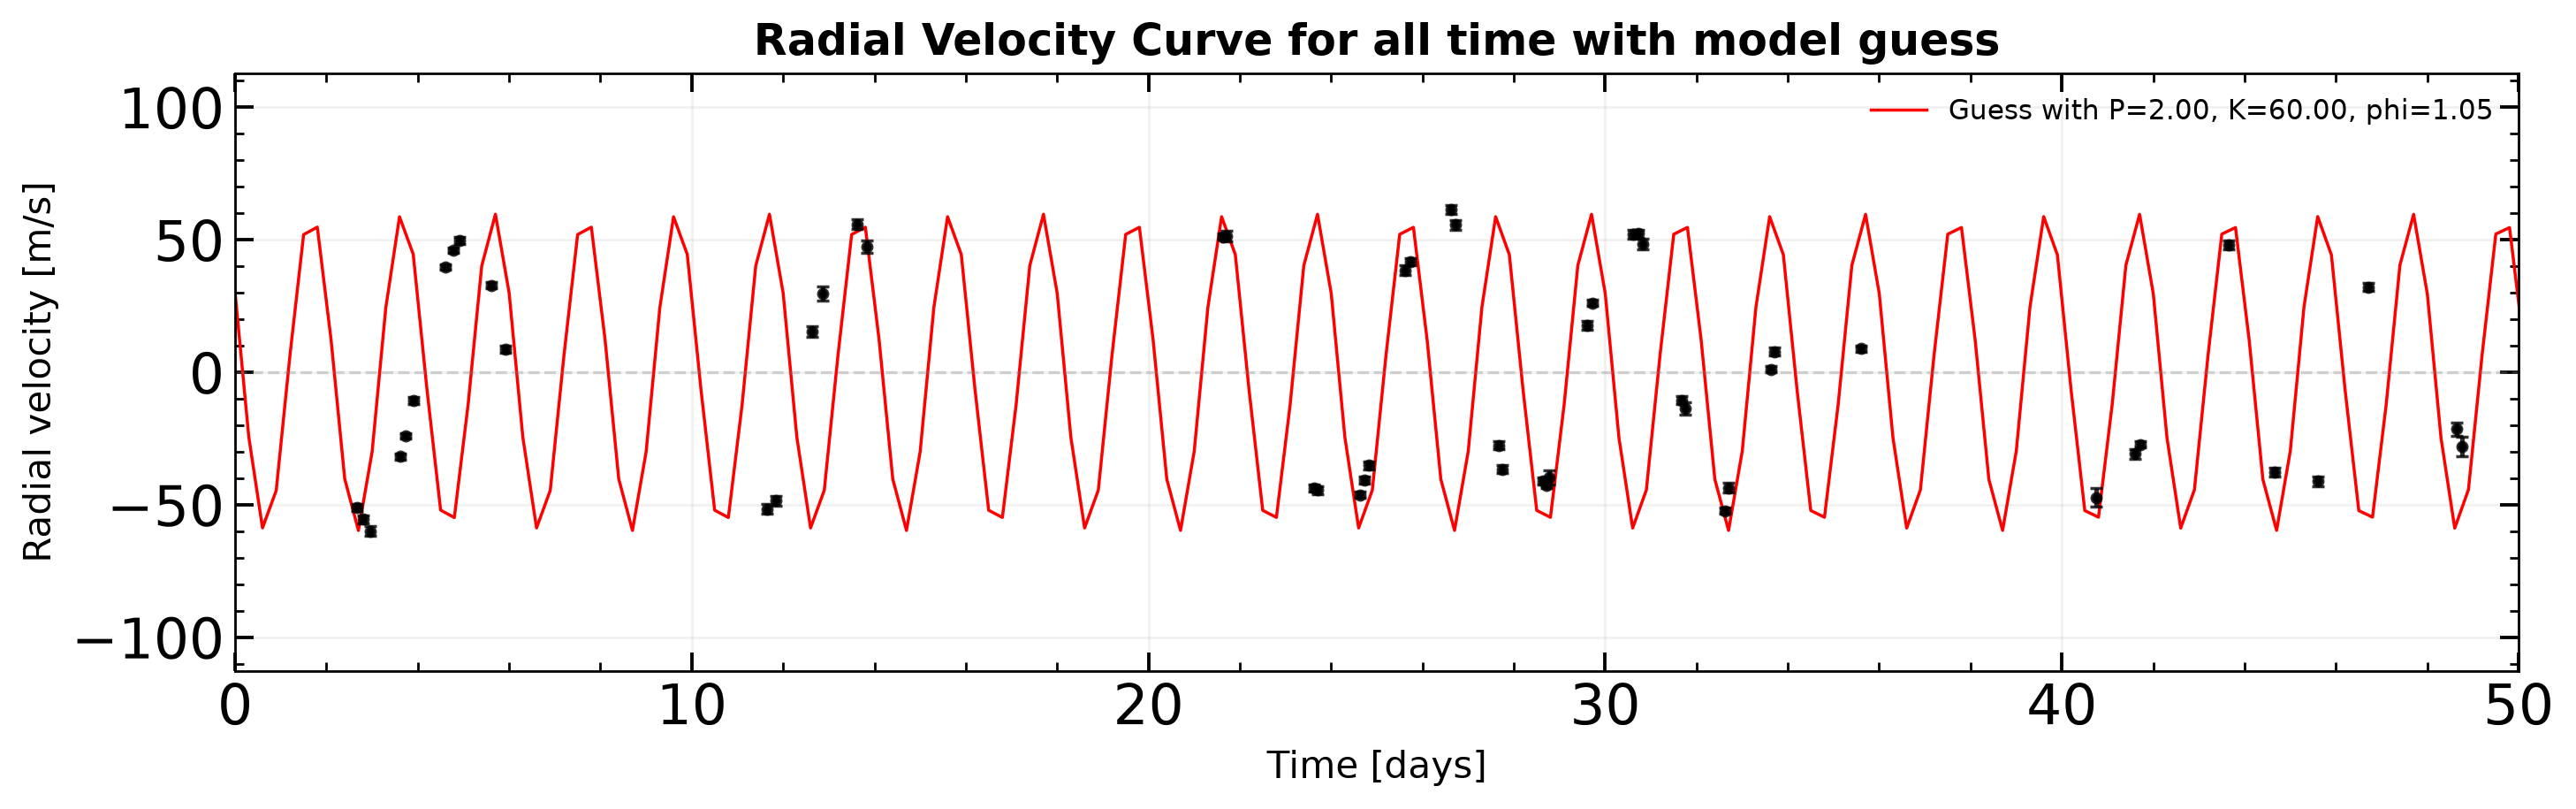

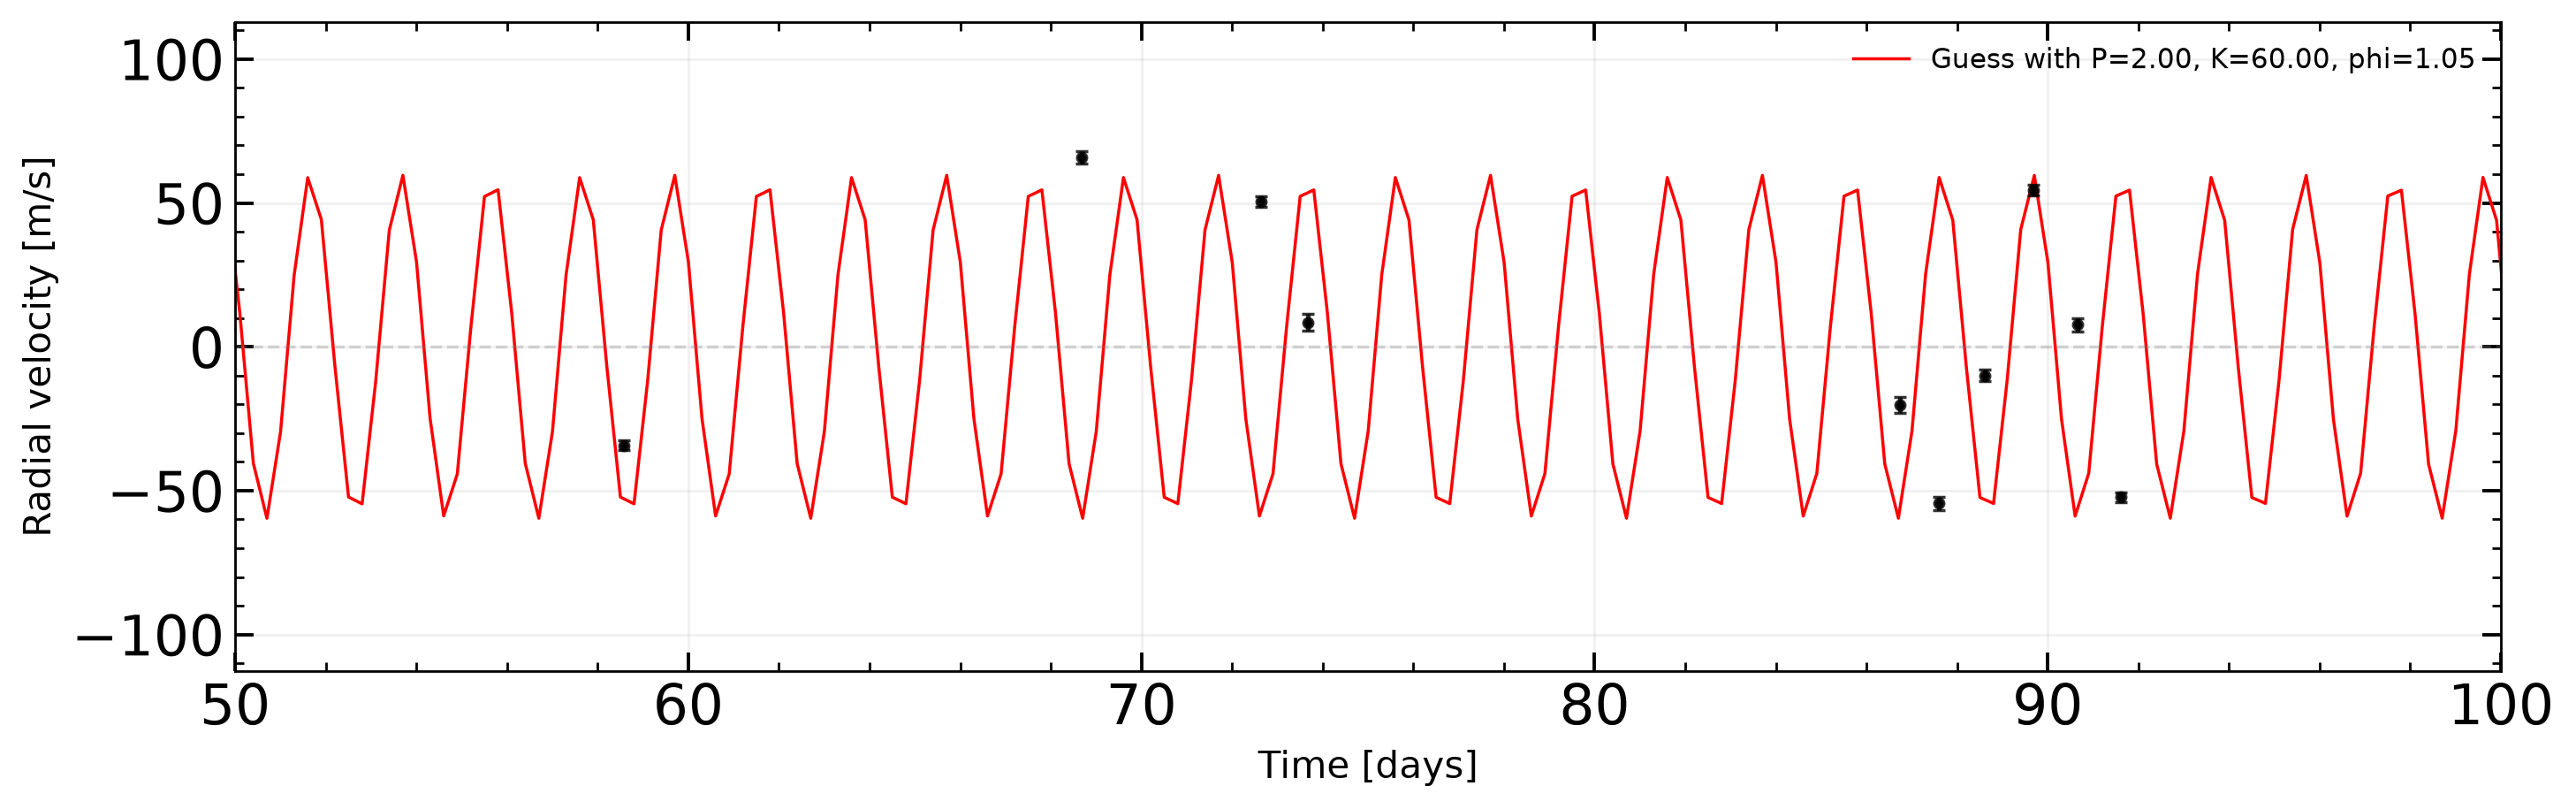

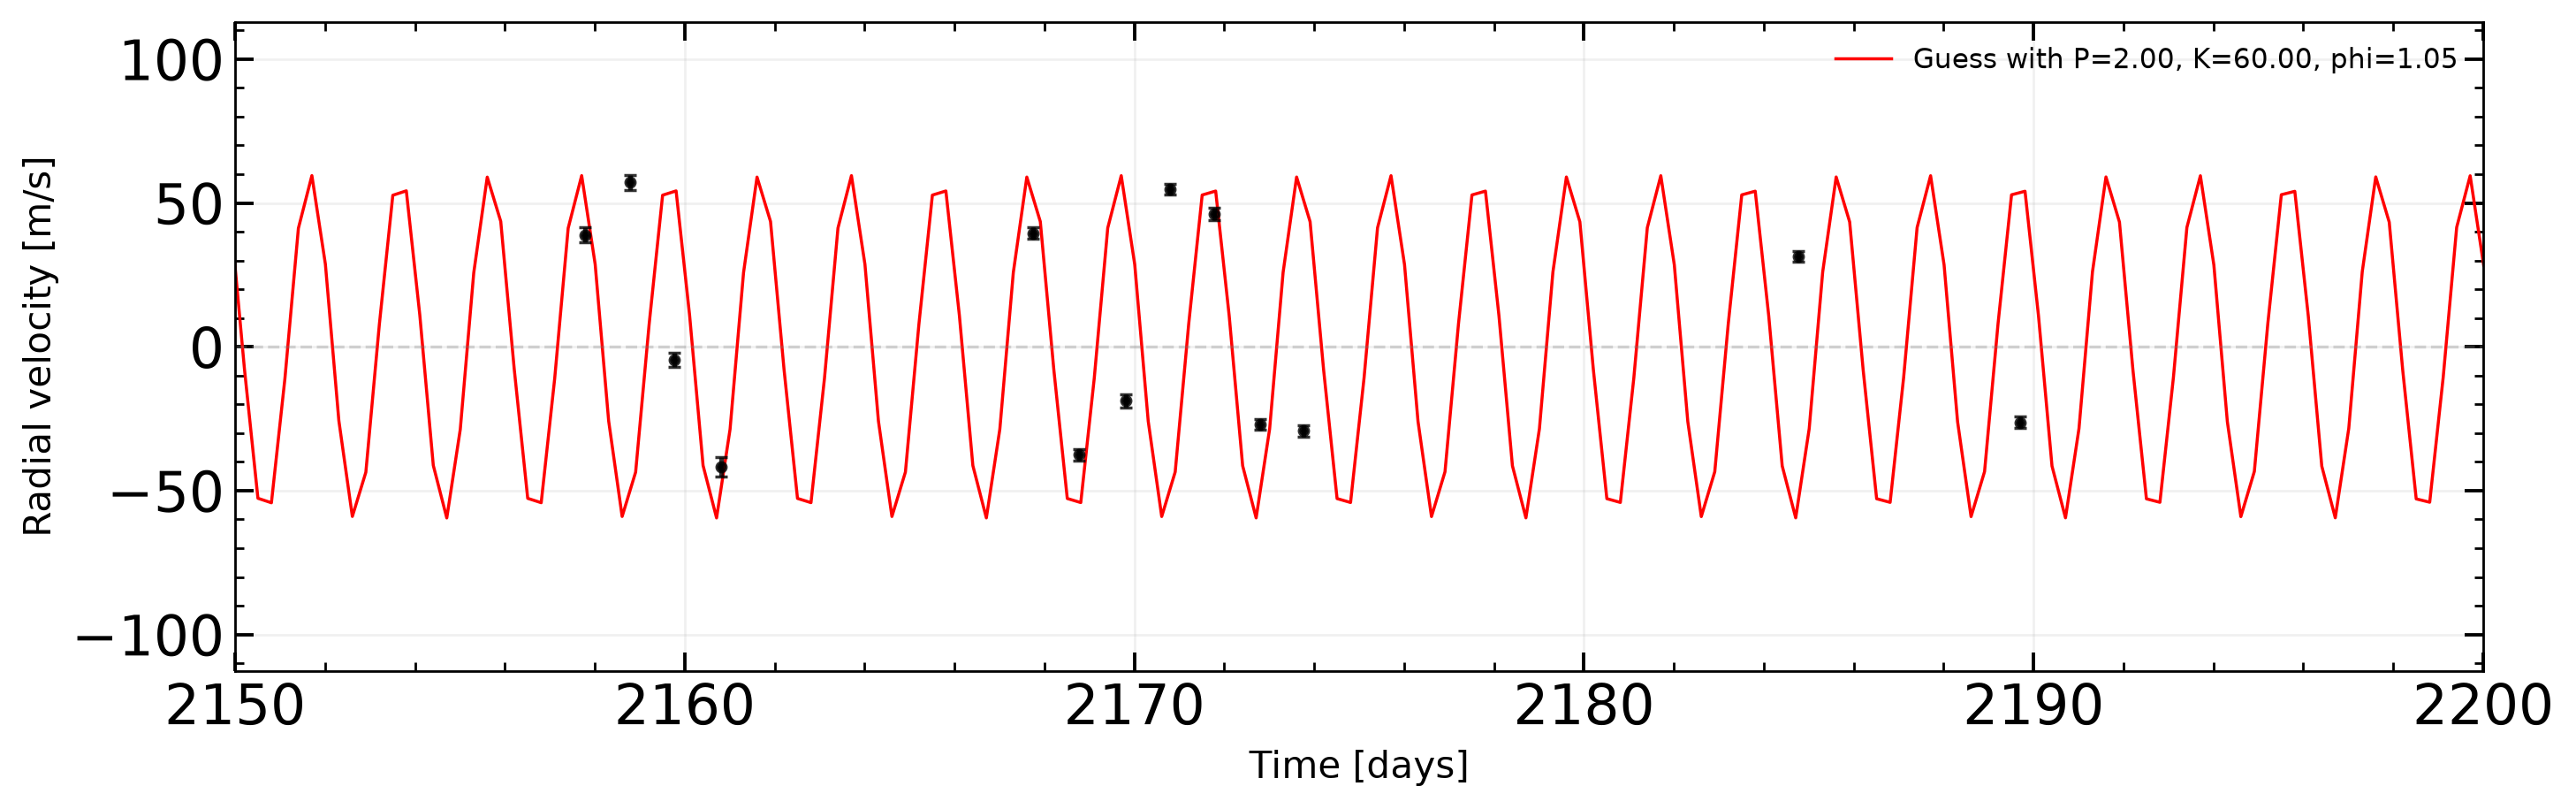

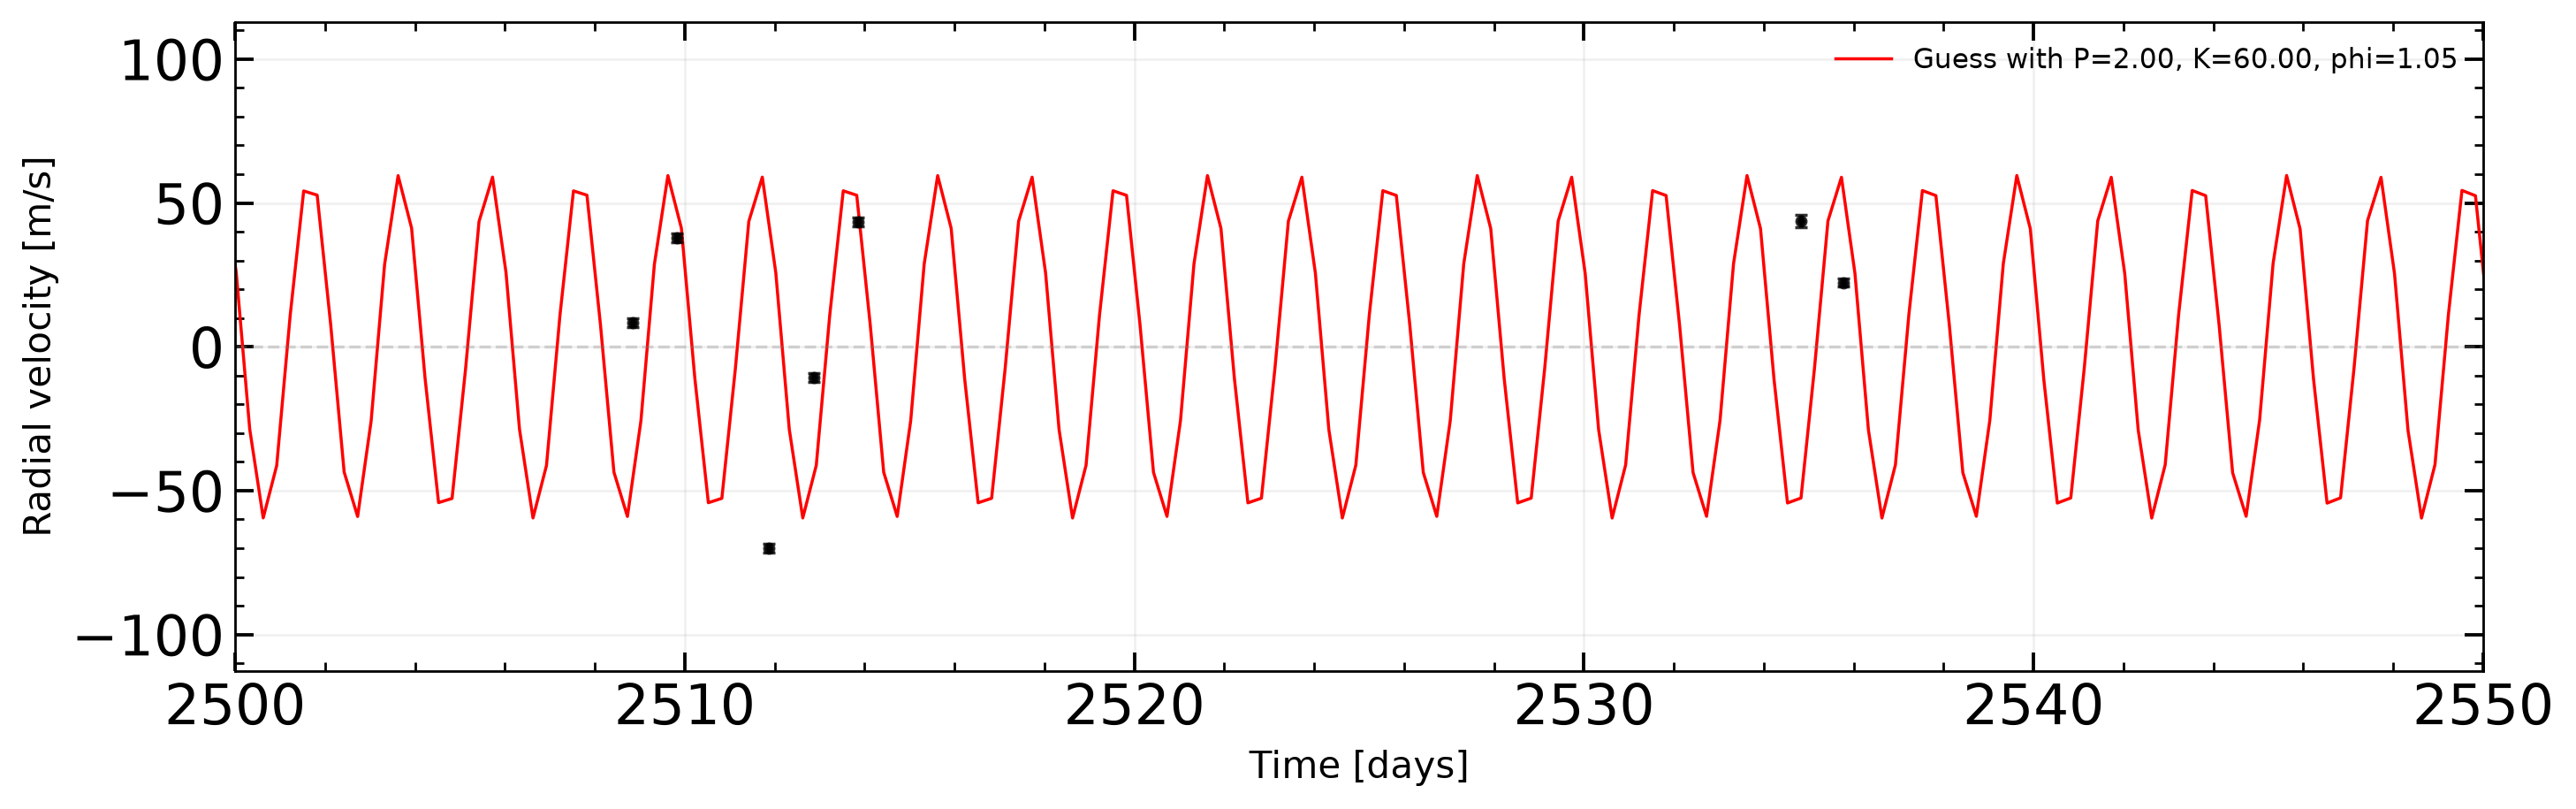

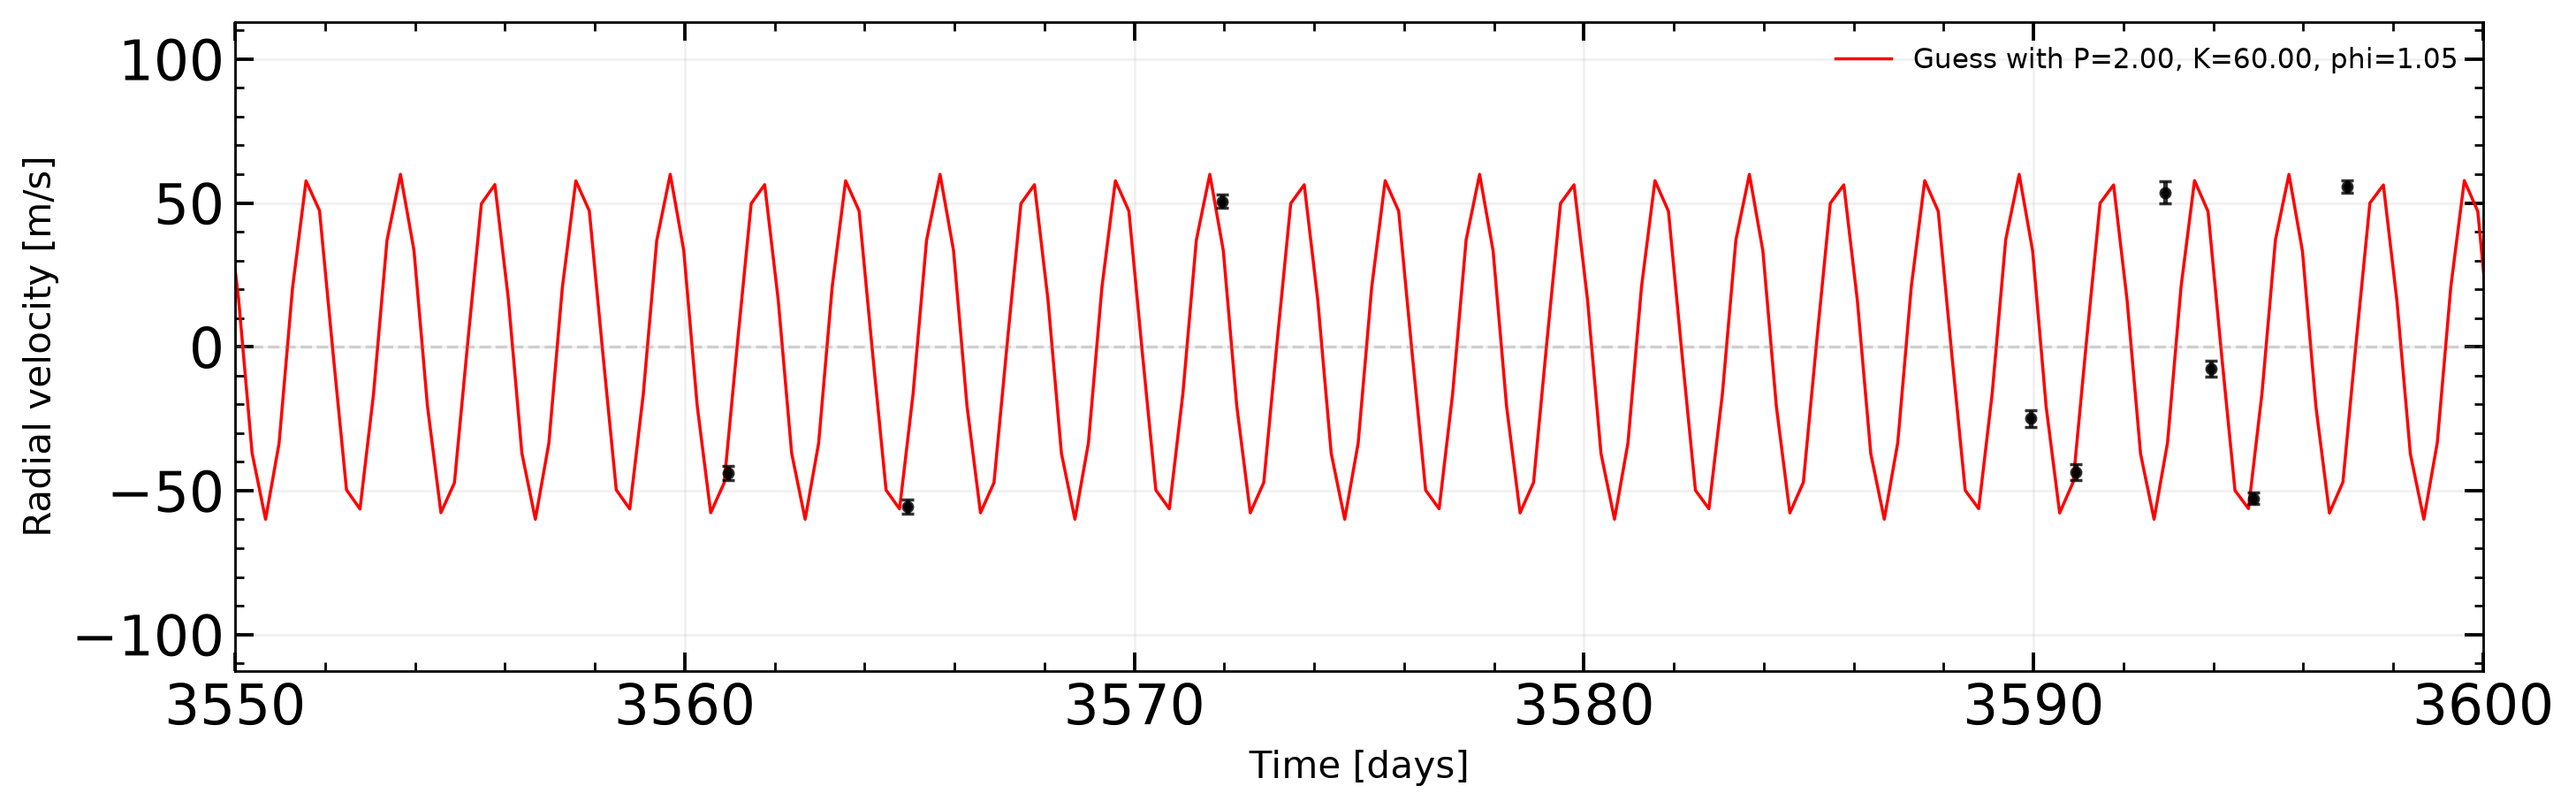

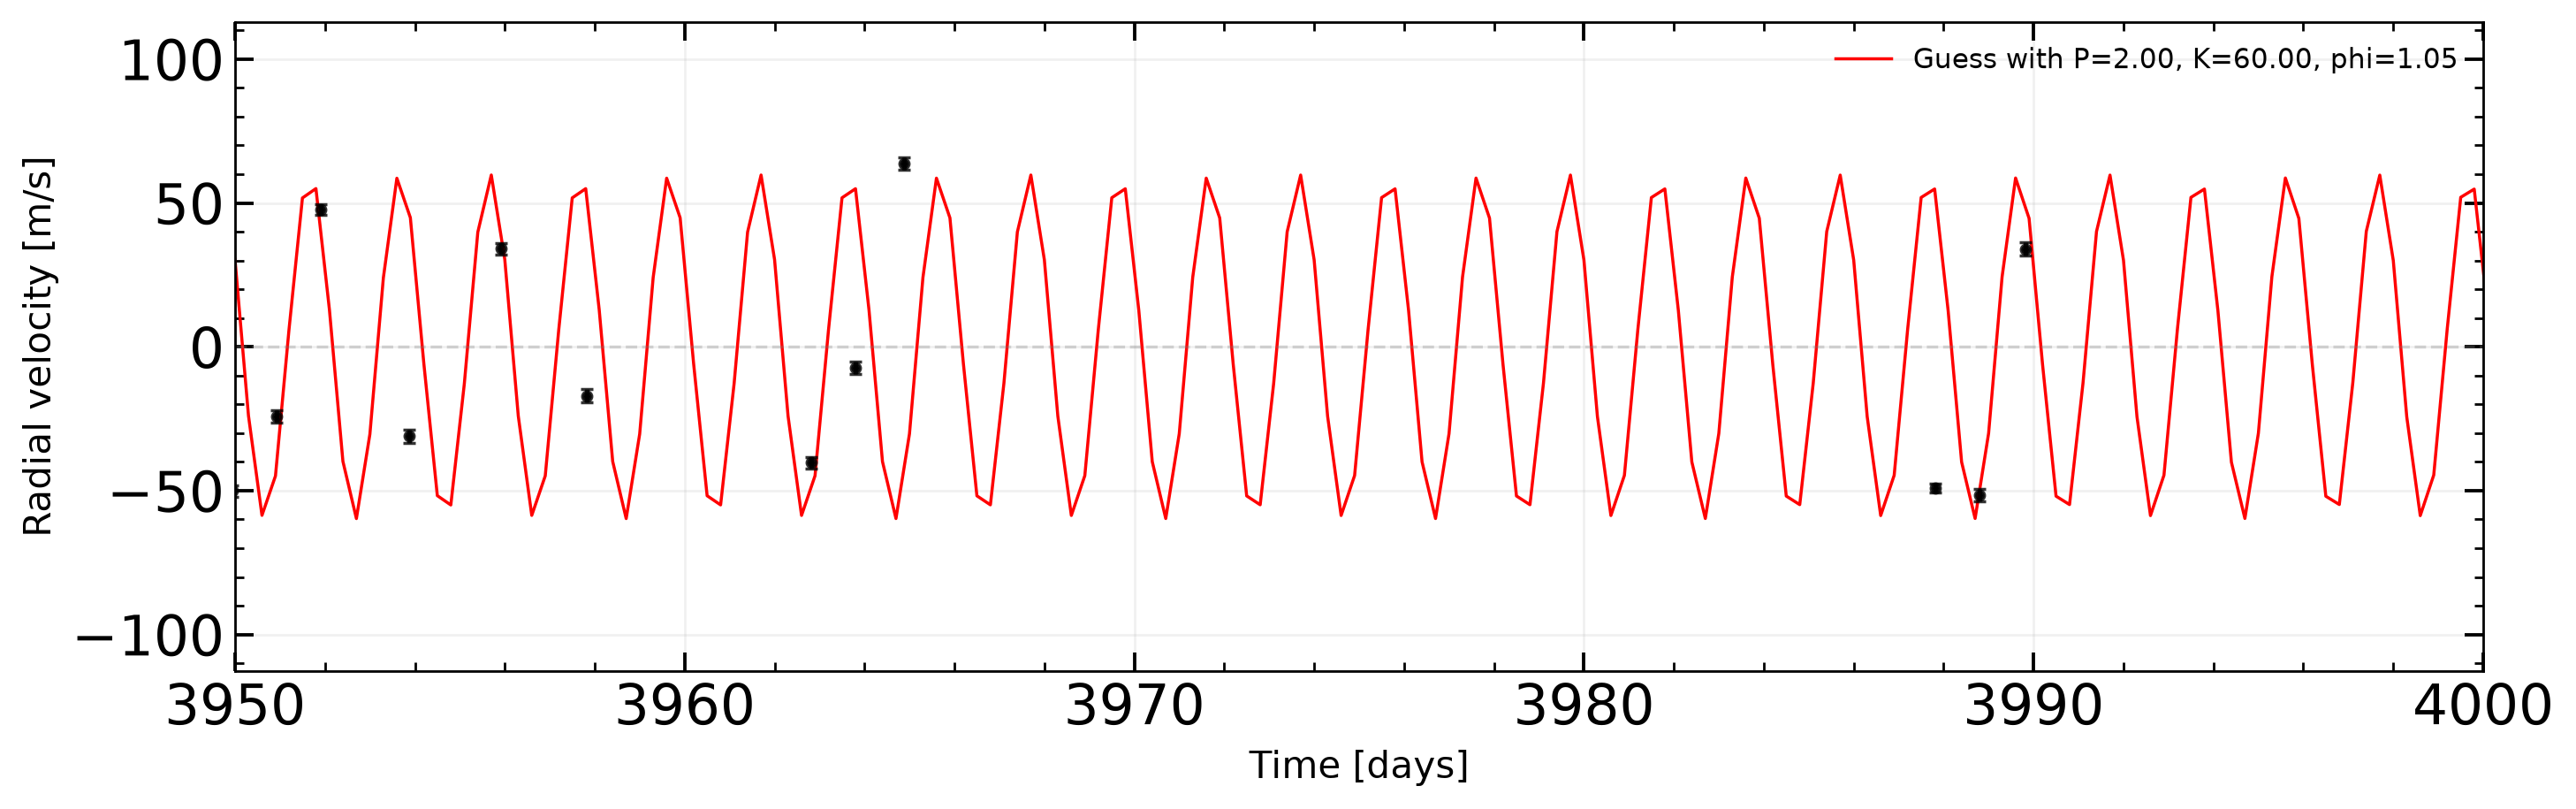

In [26]:
# fine time resolution for guess so that it's a smooth curve 
t_plot = np.linspace(0, 6000, 20000)   # 20000 steps from 0 to 6000 days

# guess curve 
v_plot = RV(P, K, phi, t_plot)


step = 50
for i,start in enumerate(np.arange(0, 6000, step)):
    end = start + step
    sel = np.logical_and(time > start, time < end)
    
    # Only plot the figure if there are a reasonable number of points in the range
    if len(time[sel]) > 6:
        # fig = plt.figure(num=i, figsize=[12.,2.], dpi=200)
        # plt.errorbar(time[sel],v[sel],err[sel],marker='o',ls='')
        # plt.xlim((start,start+50))
        # plt.xlabel("Days")
        # plt.ylabel("Vel")

        fig, ax = plt.subplots(num = i, figsize=(12, 4), dpi=250)
        ax.scatter(time, v, color="black", s = 1.0,zorder = 2)
        ax.plot(t_plot, v_plot, color = "red", lw = 1, label = f"Guess with P={P:.2f}, K={K:.2f}, phi={phi:.2f}")

        # Error bars 
        ax.errorbar(
            time,
            v,
            yerr=err,
            fmt="o",
            ms=3.0,
            color='black',
            alpha=.8,
            capsize=2,
            #label="",
            #lw = 1
        )
        ax.axhline(0, color='gray', lw=1, ls="--", alpha=0.3)

        ax.set_xlim((start,start+50))
        # make y-limits symmetric around zero
        rv_absmax = max(abs(v.min()), abs(v.max()))
        ax.set_ylim(-1.25 * rv_absmax, 1.25 * rv_absmax)

        # ticks on all four sides
        ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.1, top=True, right=True)
        ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8, top=True, right=True)
        ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
        ax.grid(True, which="major", alpha=0.18, lw=0.8)
        ax.legend(frameon=False, fontsize=9, loc="best")
        ax.set_xlabel("Time [days]", fontsize=12)
        ax.set_ylabel("Radial velocity [m/s]", fontsize=12)
        ax.set_title("Radial Velocity Curve for all time with model guess", fontsize=14, fontweight="bold") if i==0 else ax.set_title("")
        fig.tight_layout()

instead of just guessing like this I will try to use a periodogram to get a better guess for the Period.

### Using a periodogram

---

# Q2

## MCMC

The goal is to _write your own Metropolis-Hastings MCMC code_, to find the best fit and its uncertainties in the parameters.

* You can follow the ideas [here](http://twiecki.github.io/) or [here](http://dfm.io/emcee/current/user/line/#the-generative-probabilistic-model) - note the use of priors to exclude regions of parameter space that you do not wish to fit.

* You should test your MCMC code on an easy case with known solution (e.g. a straight line fit with known parameters and simulated data that you generate yourself).

## Application to the above time series from Q1

You will need a good starting guess not only for the values of the parameters but also for the _range_, so that you can make a sensible proposal distribution.

Try a range of proposal distributions and a range of starting guesses (including some local-not-global minima).

Plot the chains and results and comment on the behaviour of the chains.

Once you have a final fit to _all_ of the data from your MCMC code, 

1. Make a _corner plot_ of the fitted parameters (you can use the package)
2. Plot the best fit velocity curve on top of the data (as described above), and show the range allowed by the fitted parameter uncertainties as a light shaded band.

_Show your final work as well as all your exploratory work and tests_. 

Use as many cells as you need, mixing Markdown/LaTeX with code, as necessary.

---

## Start of my solution

---